# Trabalho Prático I — Análise Exploratória, Estacionariedade e Modelagem Autoregressiva em Séries Temporais

**Disciplina:** Séries Temporais e Aprendizagem Supervisionada II<br>
**Professor:** Gildo Leonel<br>
**Autoria:** Sophia Cristine Soares Mello<br>
**Data:** outubro de 2026

> **Série analisada:** índice de volume de vendas no comércio varejista do Brasil — Pesquisa Mensal de Comércio (PMC/IBGE), mensal, de janeiro de 2000 a julho de 2026 (**n = 319**).

**Roteiro**

| Seção | Conteúdo |
|---|---|
| 0 | Contexto, fonte e carregamento dos dados |
| Etapa 1 | Visualização bruta e decomposição clássica (`seasonal_decompose`) |
| Etapa 2 | Transformação em aprendizado supervisionado (janelas deslizantes) |
| Etapa 3 | Estacionariedade (teste ADF) e diferenciação |
| Etapa 4 | FAC/FACP e seleção de atributos (lags) |
| - | Modelo autoregressivo (OLS) com os lags selecionados pela FACP |
| Etapa 5 | Considerações finais e avaliação pessoal |

## 0. Contexto do problema e fonte dos dados

A **Pesquisa Mensal de Comércio (PMC)** do IBGE acompanha, mês a mês, o desempenho do comércio varejista brasileiro. Foi usado o **índice de volume de vendas do varejo** (base 2022 = 100). Como a receita é deflacionada, o índice mede quantidades vendidas, sem o efeito da inflação. O consumo das famílias é o principal componente do PIB pela ótica da demanda, então esta série funciona como um termômetro da atividade econômica, acompanhado de perto por empresas, governo e mercado financeiro.

Foi escolhido de propósito a série **sem ajuste sazonal**. O objetivo do trabalho é justamente estudar a sazonalidade (Natal, Black Friday, fevereiro mais curto), que a versão dessazonalizada já traria removida.

| Requisito do trabalho | Situação da série |
|---|---|
| Frequência regular | Mensal, sem meses faltantes |
| Tamanho mínimo (n ≥ 100) | n = 319 (jan/2000 a jul/2026) |
| Origem real e pública | IBGE, API oficial do SIDRA |
| Comportamento relevante | Tendência, sazonalidade forte (pico em dezembro) e ciclos (expansão até 2014, recessão de 2015–2016, choque da COVID-19 em 2020) |

**Fonte exata dos dados**

- **Tabela SIDRA 8880:** *Índice e variação da receita nominal e do volume de vendas no comércio varejista (2022 = 100)*, em <https://sidra.ibge.gov.br/tabela/8880>.
- **Recorte:** variável 7169 (*PMC – Número-índice, 2022 = 100*), classificação 11046 = 56734 (*Índice de volume de vendas no comércio varejista*), nível Brasil.
- **API utilizada:** `https://servicodados.ibge.gov.br/api/v3/agregados/8880/periodos/all/variaveis/7169?localidades=N1[all]&classificacao=11046[56734]`
- **Cópia local:** `data/pmc_varejo_volume_ibge.csv`, baixada em 02/10/2026. O notebook lê essa cópia por padrão, para que os números citados no texto continuem reproduzíveis mesmo depois de novas divulgações ou revisões do IBGE. Para baixar a versão mais recente, use `carregar_pmc(atualizar=True)`.

In [1]:
import gzip
import json
import urllib.request
import warnings
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
import statsmodels.api as sm
from cycler import cycler
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, pacf

# statsmodels >= 0.15 avisa que adfuller passará a devolver um objeto; seguimos com a tupla clássica
warnings.filterwarnings("ignore", message=".*currently returns a plain tuple.*", category=FutureWarning)

# Paleta categórica validada para daltonismo + tintas neutras (usadas em todos os gráficos)
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
CINZA_MARCA = "#c3c2b7"                      # marcas sem destaque, eixos e linha de base
TINTA, TINTA_2, TINTA_SUAVE = "#0b0b0b", "#52514e", "#898781"
GRADE, FUNDO = "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "figure.dpi": 110, "font.size": 10,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "axes.prop_cycle": cycler(color=[AZUL, LARANJA, VERDE_AGUA]),
    "axes.edgecolor": CINZA_MARCA, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRADE, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "axes.labelcolor": TINTA_2, "axes.labelsize": 10,
    "xtick.color": CINZA_MARCA, "ytick.color": CINZA_MARCA,
    "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": TINTA_2,
})


def formatar_eixo_anos(ax, passo=2):
    """Marca o eixo do tempo a cada `passo` anos."""
    ax.xaxis.set_major_locator(mdates.YearLocator(passo))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def estilizar_correlograma(ax, banda):
    """Aplica o estilo do notebook a um gráfico de plot_acf/plot_pacf e marca a banda ±1,96/√n."""
    for colecao in ax.collections:
        if isinstance(colecao, PolyCollection):  # faixa de confiança desenhada pelo statsmodels
            colecao.set_facecolor(AZUL)
            colecao.set_alpha(0.10)
            colecao.set_edgecolor("none")
    for linha in ax.get_lines():
        ydata = np.asarray(linha.get_ydata(), dtype=float)
        if len(ydata) == 2 and np.allclose(ydata, 0):  # linha de base em zero
            linha.set_color(CINZA_MARCA)
            linha.set_linewidth(0.8)
    for limite in (banda, -banda):
        ax.axhline(limite, color=TINTA_SUAVE, lw=0.7)


print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| statsmodels", statsmodels.__version__)

numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2 | statsmodels 0.15.0


### 0.1 Carregamento e verificação dos dados

`baixar_pmc` consulta a API do IBGE e converte o JSON em uma tabela (`data`, `indice_volume`). `carregar_pmc` usa a cópia local em CSV se ela existir; caso contrário, baixa e salva. O resultado é um `pd.Series` indexado por data com frequência mensal explícita (`MS`, início do mês), formato esperado pelas funções do `statsmodels`.

In [2]:
URL_API = (
    "https://servicodados.ibge.gov.br/api/v3/agregados/8880/periodos/all/variaveis/7169"
    "?localidades=N1[all]&classificacao=11046[56734]"
)
CAMINHO_CSV = Path("data") / "pmc_varejo_volume_ibge.csv"


def baixar_pmc(url=URL_API):
    """Baixa a série da API do IBGE (SIDRA) e devolve um DataFrame com as colunas data e indice_volume."""
    requisicao = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(requisicao, timeout=90) as resposta:
        bruto = resposta.read()
    if bruto[:2] == b"\x1f\x8b":  # a API às vezes responde comprimida (gzip)
        bruto = gzip.decompress(bruto)
    serie = json.loads(bruto.decode("utf-8"))[0]["resultados"][0]["series"][0]["serie"]
    df = pd.DataFrame({"periodo": list(serie.keys()), "valor": list(serie.values())})
    df["indice_volume"] = pd.to_numeric(df["valor"], errors="coerce")  # "..." e "-" viram NaN
    df["data"] = pd.to_datetime(df["periodo"], format="%Y%m")
    return df.dropna(subset=["indice_volume"])[["data", "indice_volume"]].sort_values("data")


def carregar_pmc(caminho=CAMINHO_CSV, atualizar=False):
    """Lê a cópia local (CSV); baixa da API se o arquivo não existir ou se atualizar=True."""
    if atualizar or not caminho.exists():
        caminho.parent.mkdir(parents=True, exist_ok=True)
        baixar_pmc().to_csv(caminho, index=False)
    df = pd.read_csv(caminho, parse_dates=["data"])
    return df.set_index("data")["indice_volume"].asfreq("MS").rename("vendas")

In [3]:
vendas = carregar_pmc()

consecutivos = vendas.index.equals(pd.date_range(vendas.index[0], periods=len(vendas), freq="MS"))
print(f"Observações: n = {len(vendas)}")
print(f"Período: {vendas.index[0]:%m/%Y} a {vendas.index[-1]:%m/%Y}")
print(f"Frequência: {vendas.index.freqstr} (mensal) | meses consecutivos: {consecutivos}")
print(f"Valores ausentes: {vendas.isna().sum()}")
print(f"Mínimo: {vendas.min():.2f} em {vendas.idxmin():%m/%Y} | Máximo: {vendas.max():.2f} em {vendas.idxmax():%m/%Y}")
vendas.describe().round(2).to_frame().T

Observações: n = 319
Período: 01/2000 a 07/2026
Frequência: MS (mensal) | meses consecutivos: True
Valores ausentes: 0
Mínimo: 43.32 em 02/2003 | Máximo: 131.81 em 12/2014


,count,mean,std,min,25%,50%,75%,max
vendas,319.0,82.1,22.33,43.32,60.48,88.95,97.74,131.81


A série está completa: 319 meses consecutivos e nenhum valor ausente, então não é preciso imputar nem reamostrar. O índice vai de 43,3 (fev/2003) a 131,8 (dez/2014).

## Etapa 1 — Preparação dos dados e decomposição clássica

### 1.1 Visualização bruta

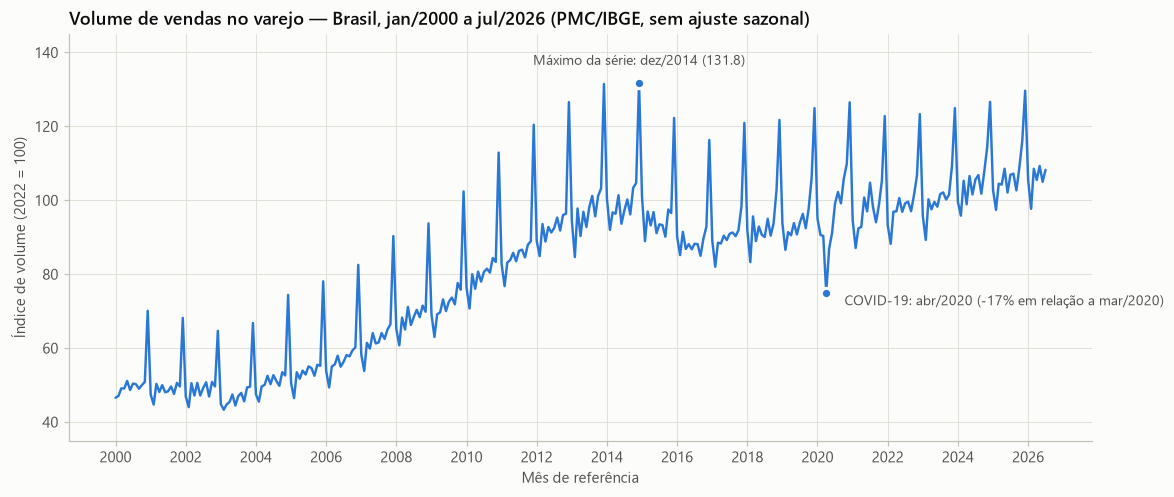

In [4]:
queda_covid = vendas["2020-04-01"] / vendas["2020-03-01"] - 1

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(vendas.index, vendas.values, color=AZUL)
ax.set_title("Volume de vendas no varejo — Brasil, jan/2000 a jul/2026 (PMC/IBGE, sem ajuste sazonal)")
ax.set_xlabel("Mês de referência")
ax.set_ylabel("Índice de volume (2022 = 100)")
ax.set_ylim(35, 145)
formatar_eixo_anos(ax)

destaques = [
    (vendas.idxmax(), f"Máximo da série: dez/2014 ({vendas.max():.1f})", (0, 14), "center"),
    (pd.Timestamp("2020-04-01"), f"COVID-19: abr/2020 ({queda_covid:+.0%} em relação a mar/2020)", (12, -6), "left"),
]
for data, texto, deslocamento, alinhamento in destaques:
    ax.scatter(data, vendas[data], s=46, color=AZUL, edgecolors=FUNDO, linewidths=2, zorder=3)
    ax.annotate(texto, xy=(data, vendas[data]), xytext=deslocamento, textcoords="offset points",
                ha=alinhamento, va="center", fontsize=9, color=TINTA_2)
plt.show()

**O que o gráfico mostra**

- **Tendência com ciclos.** O índice mais que dobra entre 2003 e 2014, no ciclo de expansão da renda e do crédito. Cai na recessão de 2015–2016, se recupera devagar e só volta a superar o nível de 2014 a partir de 2023.
- **Sazonalidade forte e regular.** Há um pico em todo mês de dezembro (Natal) e um vale em fevereiro (mês mais curto, depois das festas e das compras de janeiro).
- **Choque pontual.** Em abril de 2020, o isolamento social da COVID-19 derrubou o índice em cerca de 17% em relação a março, mas a perda foi recuperada em poucos meses. É um choque transitório, não uma mudança de nível.
- **Amplitude sazonal que acompanha o nível.** Os picos de dezembro ficam mais altos à medida que a série sobe. É a primeira pista de que o modelo multiplicativo pode ser o mais adequado, hipótese testada na seção 1.3.

### 1.2 Decomposição estrutural

A decomposição clássica separa a série em três componentes:

- **Tendência ($T_t$):** movimento de longo prazo, estimado por uma média móvel centrada de 12 meses (2×12). Por isso, os 6 primeiros e os 6 últimos meses ficam sem tendência estimada.
- **Sazonalidade ($S_t$):** padrão que se repete a cada 12 meses. É estimado pela média de cada mês do calendário depois de retirar a tendência e, na decomposição clássica, é **o mesmo em todos os anos**.
- **Ruído/resíduo ($\varepsilon_t$):** o que sobra, ou seja, os choques irregulares que a tendência e a sazonalidade não explicam.

Esses componentes podem ser combinados de duas formas:

$$\text{Aditivo: } y_t = T_t + S_t + \varepsilon_t \qquad\qquad \text{Multiplicativo: } y_t = T_t \times S_t \times \varepsilon_t$$

No modelo aditivo, a sazonalidade soma ou subtrai uma quantidade fixa de pontos do índice. No multiplicativo, ela é uma **proporção** do nível (por exemplo, "dezembro vende 30% acima da tendência"). Abaixo aplicamos `seasonal_decompose` com os dois modelos. A escolha entre eles é feita na seção 1.3.

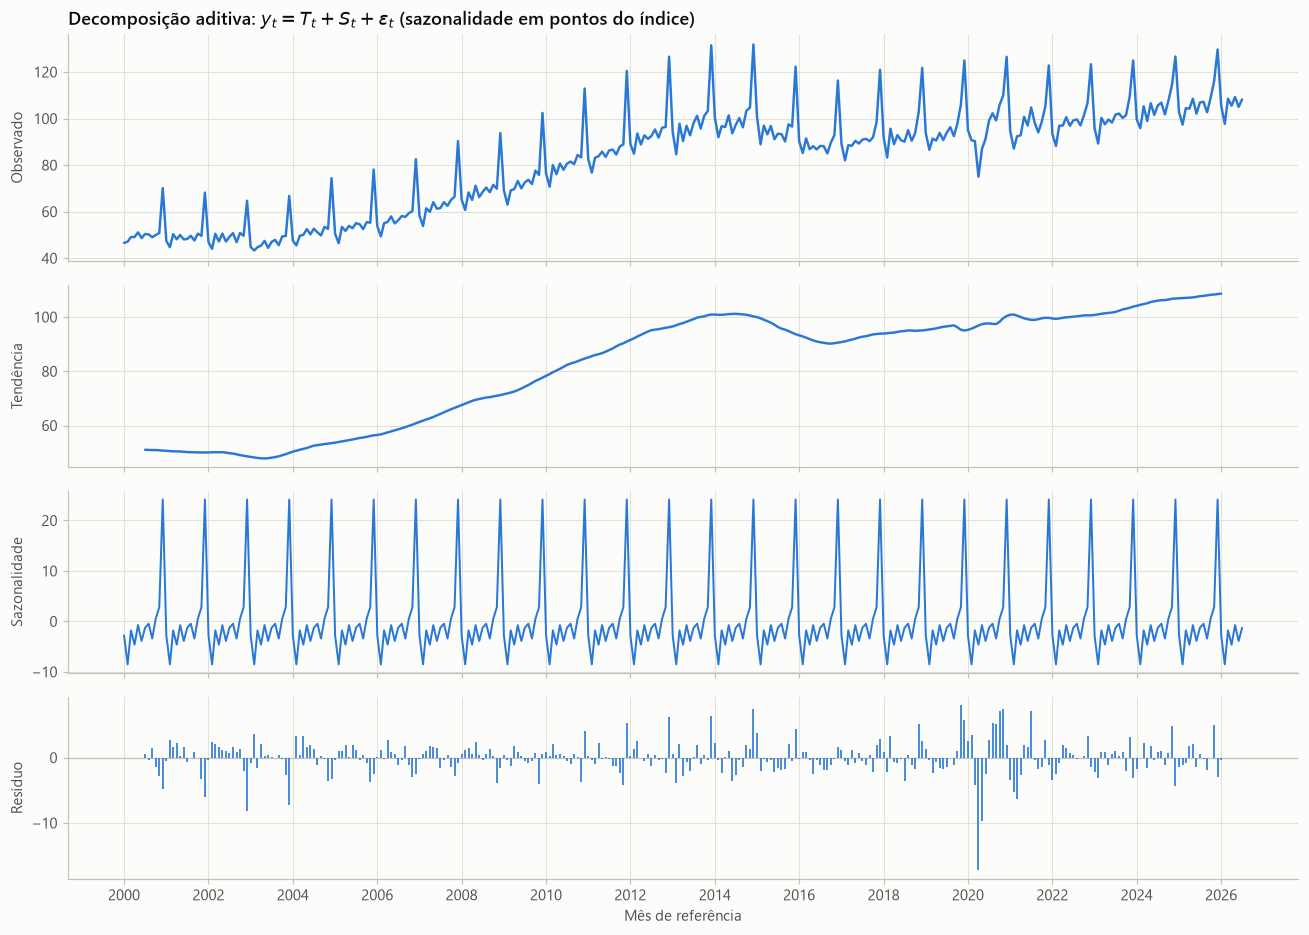

In [5]:
def plot_decomposicao(dec, titulo, base_residuo):
    """Plota observado, tendência, sazonalidade e resíduo de um seasonal_decompose em 4 painéis."""
    fig, axs = plt.subplots(4, 1, figsize=(12, 8.6), sharex=True,
                            gridspec_kw={"height_ratios": [1.25, 1, 1, 1]})
    componentes = [(dec.observed, "Observado"), (dec.trend, "Tendência"),
                   (dec.seasonal, "Sazonalidade"), (dec.resid, "Resíduo")]
    for ax, (serie, rotulo) in zip(axs, componentes):
        if rotulo == "Resíduo":
            resid = serie.dropna()
            ax.axhline(base_residuo, color=CINZA_MARCA, lw=0.8)
            ax.vlines(resid.index, base_residuo, resid.values, color=AZUL, lw=1.1)
        else:
            ax.plot(serie.index, serie.values, color=AZUL, lw=1.3 if rotulo == "Sazonalidade" else 1.6)
        ax.set_ylabel(rotulo)
    axs[0].set_title(titulo)
    axs[-1].set_xlabel("Mês de referência")
    formatar_eixo_anos(axs[-1])
    fig.align_ylabels(axs)
    plt.tight_layout()
    plt.show()


dec_adit = seasonal_decompose(vendas, model="additive", period=12)
dec_mult = seasonal_decompose(vendas, model="multiplicative", period=12)

plot_decomposicao(dec_adit, r"Decomposição aditiva: $y_t = T_t + S_t + \varepsilon_t$ (sazonalidade em pontos do índice)",
                  base_residuo=0)

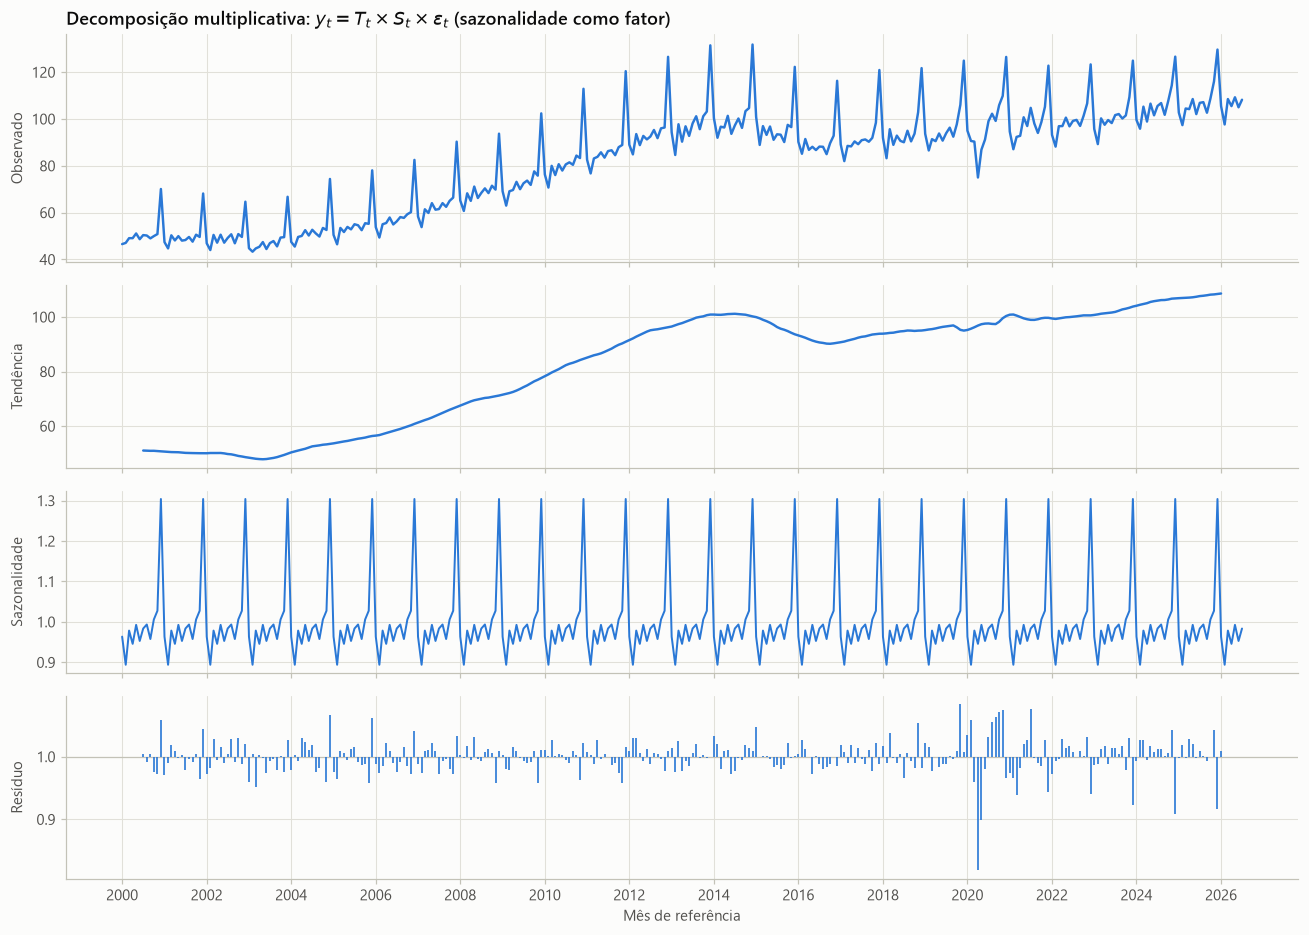

In [6]:
plot_decomposicao(dec_mult, r"Decomposição multiplicativa: $y_t = T_t \times S_t \times \varepsilon_t$ (sazonalidade como fator)",
                  base_residuo=1)

**Leitura das decomposições**

- A **tendência** é a mesma nos dois modelos (mesma média móvel) e resume os ciclos descritos em 1.1.
- A **sazonalidade** tem o mesmo desenho nos dois casos: pico em dezembro e vale em fevereiro. No modelo aditivo ela é medida em pontos do índice; no multiplicativo, como fator (1,30 significa 30% acima da tendência).
- O **resíduo** concentra o choque da COVID-19 (abril e maio de 2020) e, nos anos recentes, dezembros com resíduo negativo, um sinal de que o padrão sazonal mudou. Isso é analisado a seguir.

### 1.3 Análise crítica: modelo aditivo ou multiplicativo?

O critério é como a **amplitude sazonal** se comporta quando o nível da série muda. Se ela é constante em pontos do índice, o modelo é aditivo. Se cresce junto com o nível, mantendo-se constante *em proporção*, o modelo é multiplicativo. Para medir isso, calculamos ano a ano:

- **nível:** média da tendência $T_t$ no ano;
- **amplitude absoluta:** desvio-padrão de $y_t - T_t$ no ano, em pontos do índice;
- **amplitude relativa:** desvio-padrão de $y_t / T_t$ no ano, em proporção do nível.

Um resumo útil é a **elasticidade** $\beta$ da amplitude absoluta em relação ao nível, que é a inclinação de $\log(\text{amplitude}) = \alpha + \beta \log(\text{nível})$. No modelo aditivo a amplitude não depende do nível ($\beta \approx 0$). No multiplicativo ela é proporcional ao nível ($\beta \approx 1$).

In [7]:
tendencia = dec_mult.trend
anos_completos = tendencia.dropna().index.year.value_counts().loc[lambda c: c == 12].index.sort_values()

amplitude = pd.DataFrame({
    "nível (média de T)": tendencia.groupby(tendencia.index.year).mean(),
    "amplitude absoluta: dp(y − T)": (vendas - tendencia).groupby(vendas.index.year).std(),
    "amplitude relativa: dp(y / T)": (vendas / tendencia).groupby(vendas.index.year).std(),
}).loc[anos_completos]
amplitude.index.name = "ano"


def elasticidade(tabela):
    """Inclinação da regressão log(amplitude absoluta) ~ log(nível)."""
    return np.polyfit(np.log(tabela.iloc[:, 0]), np.log(tabela.iloc[:, 1]), 1)[0]


nivel, amp_abs, amp_rel = (amplitude.iloc[:, i] for i in range(3))
print("Elasticidade da amplitude sazonal em relação ao nível (aditivo: β ≈ 0 | multiplicativo: β ≈ 1)")
print(f"  2001–2014: β = {elasticidade(amplitude.loc[2001:2014]):.2f}")
print(f"  2001–2025: β = {elasticidade(amplitude):.2f}")
print(f"Correlação nível × amplitude absoluta (2001–2025): {nivel.corr(amp_abs):+.2f}")
print(f"\nDe 2003 para 2014: nível {nivel[2014] / nivel[2003] - 1:+.0%} | amplitude absoluta "
      f"{amp_abs[2014] / amp_abs[2003] - 1:+.0%} | amplitude relativa {amp_rel[2014] / amp_rel[2003] - 1:+.0%}")
amplitude.loc[[2003, 2008, 2014, 2016, 2019, 2022, 2025]].round(3)

Elasticidade da amplitude sazonal em relação ao nível (aditivo: β ≈ 0 | multiplicativo: β ≈ 1)
  2001–2014: β = 0.79
  2001–2025: β = 0.59
Correlação nível × amplitude absoluta (2001–2025): +0.75

De 2003 para 2014: nível +108% | amplitude absoluta +85% | amplitude relativa -9%


,nível (média de T),amplitude absoluta: dp(y − T),amplitude relativa: dp(y / T)
ano,,,
2003,48.492,5.720,0.115
2008,69.681,7.423,0.105
2014,100.874,10.581,0.105
2016,91.267,8.683,0.096
2019,95.945,10.441,0.110
2022,100.036,8.272,0.082
2025,107.589,7.944,0.073


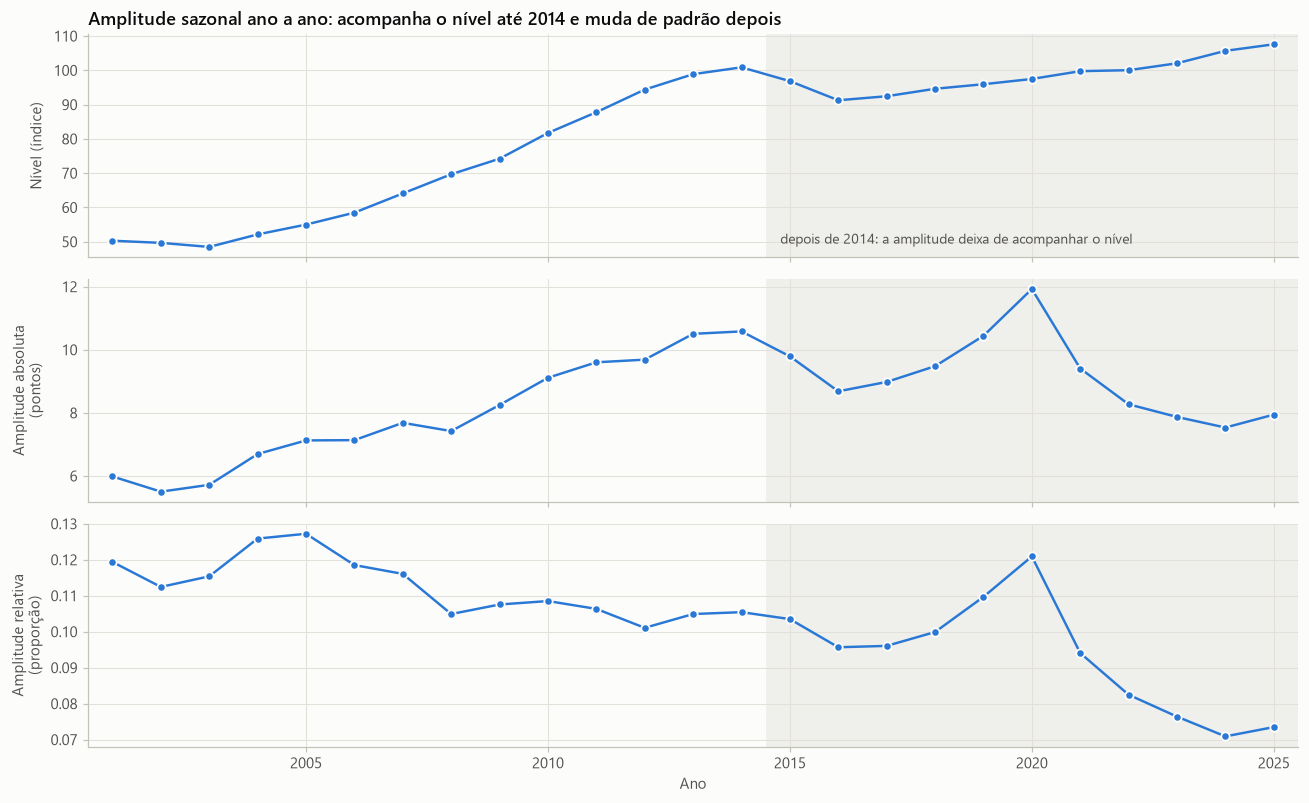

In [8]:
fig, axs = plt.subplots(3, 1, figsize=(12, 7.4), sharex=True)
paineis = [
    ("nível (média de T)", "Nível (índice)"),
    ("amplitude absoluta: dp(y − T)", "Amplitude absoluta\n(pontos)"),
    ("amplitude relativa: dp(y / T)", "Amplitude relativa\n(proporção)"),
]
for ax, (coluna, rotulo) in zip(axs, paineis):
    ax.axvspan(2014.5, amplitude.index.max() + 0.5, color=GRADE, alpha=0.45, lw=0)
    ax.plot(amplitude.index, amplitude[coluna], color=AZUL, marker="o", markersize=5.5,
            markeredgecolor=FUNDO, markeredgewidth=1.2)
    ax.set_ylabel(rotulo)
axs[0].set_title("Amplitude sazonal ano a ano: acompanha o nível até 2014 e muda de padrão depois")
axs[0].text(2014.8, axs[0].get_ylim()[0] + 0.06 * np.ptp(axs[0].get_ylim()),
            "depois de 2014: a amplitude deixa de acompanhar o nível", fontsize=9, color=TINTA_2)
axs[-1].set_xlabel("Ano")
axs[-1].set_xlim(amplitude.index.min() - 0.5, amplitude.index.max() + 0.5)
fig.align_ylabels(axs)
plt.tight_layout()
plt.show()

**O que os números mostram**

- **De 2001 a 2014, a amplitude acompanhou o nível.** Entre 2003 e 2014, o nível subiu 108% e a amplitude absoluta, 85%, enquanto a amplitude relativa quase não mudou (−9%). A elasticidade nesse período é **β = 0,79**, muito mais perto de 1 (multiplicativo) do que de 0 (aditivo). Na amostra inteira, a correlação entre nível e amplitude absoluta é de +0,75.
- **Depois de 2014, a relação se enfraquece.** O nível volta a subir a partir de 2017, mas a amplitude absoluta cai depois de 2020, e a elasticidade da amostra completa recua para **β = 0,59**. Os picos de 2019 e 2020 têm causas pontuais: novembro de 2019 ficou bem acima do padrão (o maior resíduo positivo da série) e 2020 teve o choque da COVID-19. Já a queda depois de 2020 reflete uma mudança no próprio padrão sazonal, investigada abaixo.

In [9]:
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
fatores = dec_mult.seasonal.iloc[:12].to_numpy()  # a série começa em janeiro: ordem jan..dez
pd.DataFrame({"fator sazonal (S)": fatores.round(3),
              "efeito em relação à tendência": [f"{f - 1:+.1%}" for f in fatores]},
             index=pd.Index(meses, name="mês")).T

mês,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
fator sazonal (S),0.964,0.894,0.979,0.946,0.993,0.953,0.984,0.994,0.958,1.006,1.028,1.304
efeito em relação à tendência,-3.6%,-10.6%,-2.1%,-5.4%,-0.7%,-4.7%,-1.6%,-0.6%,-4.2%,+0.6%,+2.8%,+30.4%


Os fatores sazonais do modelo multiplicativo mostram o "calendário" do varejo: **dezembro vende cerca de 30% acima da tendência** e **fevereiro, cerca de 11% abaixo**. Os demais meses ficam a poucos pontos percentuais da tendência.

#### A sazonalidade mudou ao longo do tempo

A decomposição clássica supõe um padrão sazonal **fixo**: o mesmo fator de dezembro vale para 2001 e para 2025. A queda da amplitude relativa depois de 2014 indica que essa hipótese não se sustenta. Para investigar, comparamos novembro e dezembro com a média de cada ano.

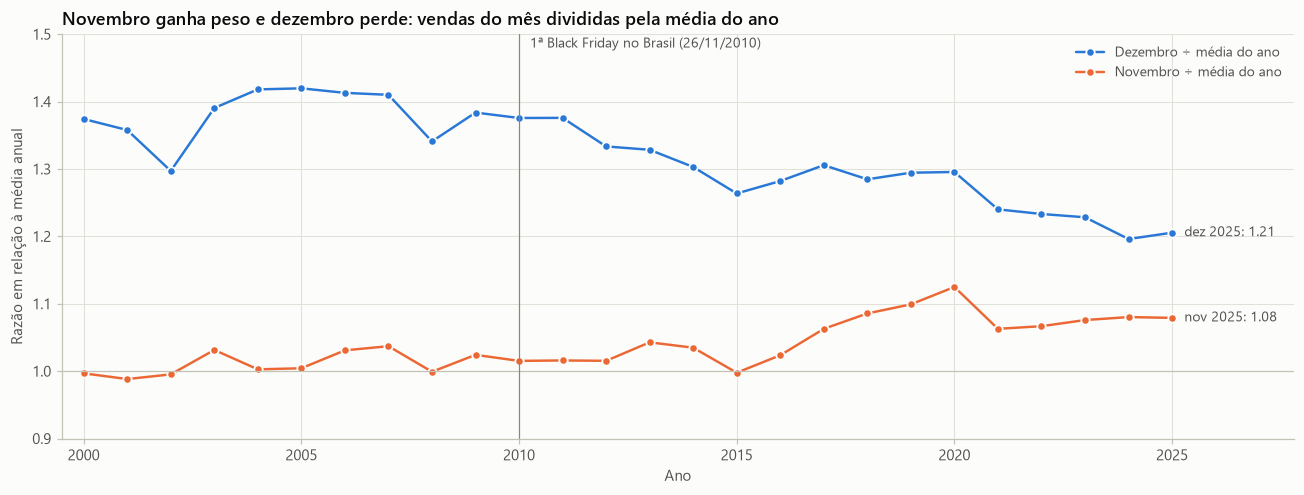

Dezembro ÷ média: 1.38 (2000–2009) -> 1.22 (2021–2025)
Novembro ÷ média: 1.01 (2000–2009) -> 1.07 (2021–2025)


In [10]:
tabela_anual = (vendas.to_frame("v")
                .assign(ano=vendas.index.year, mes=vendas.index.month)
                .pivot_table(index="ano", columns="mes", values="v")
                .dropna())  # só anos completos (2000–2025)
media_anual = tabela_anual.mean(axis=1)
peso_nov = tabela_anual[11] / media_anual
peso_dez = tabela_anual[12] / media_anual

fig, ax = plt.subplots(figsize=(12, 4.6))
estilo_pontos = dict(marker="o", markersize=5.5, markeredgecolor=FUNDO, markeredgewidth=1.2)
ax.plot(peso_dez.index, peso_dez, color=AZUL, label="Dezembro ÷ média do ano", **estilo_pontos)
ax.plot(peso_nov.index, peso_nov, color=LARANJA, label="Novembro ÷ média do ano", **estilo_pontos)
ax.axhline(1, color=CINZA_MARCA, lw=0.8)
ax.axvline(2010, color=TINTA_SUAVE, lw=0.8)
ax.text(2010.25, 1.495, "1ª Black Friday no Brasil (26/11/2010)", fontsize=9, color=TINTA_2, va="top")
for serie, nome in [(peso_dez, "dez"), (peso_nov, "nov")]:
    ax.annotate(f"{nome} {serie.index[-1]}: {serie.iloc[-1]:.2f}", xy=(serie.index[-1], serie.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA_2)
ax.set_title("Novembro ganha peso e dezembro perde: vendas do mês divididas pela média do ano")
ax.set_xlabel("Ano")
ax.set_ylabel("Razão em relação à média anual")
ax.set_ylim(0.9, 1.5)
ax.set_xlim(1999.5, 2027.8)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Dezembro ÷ média: {peso_dez.loc[2000:2009].mean():.2f} (2000–2009) -> {peso_dez.loc[2021:2025].mean():.2f} (2021–2025)")
print(f"Novembro ÷ média: {peso_nov.loc[2000:2009].mean():.2f} (2000–2009) -> {peso_nov.loc[2021:2025].mean():.2f} (2021–2025)")

In [11]:
residuo = dec_mult.resid.dropna()
extremos = pd.concat([residuo.nsmallest(5), residuo.nlargest(3)])
pd.DataFrame({"resíduo (fator)": extremos.round(3).to_numpy(),
              "desvio em relação a T × S": [f"{r - 1:+.1%}" for r in extremos]},
             index=pd.Index([f"{meses[d.month - 1]}/{d.year}" for d in extremos.index], name="mês"))

,resíduo (fator),desvio em relação a T × S
mês,,
abr/2020,0.819,-18.1%
mai/2020,0.899,-10.1%
dez/2024,0.909,-9.1%
dez/2025,0.917,-8.3%
dez/2023,0.923,-7.7%
nov/2019,1.083,+8.3%
jul/2021,1.076,+7.6%
nov/2020,1.074,+7.4%


Os resíduos confirmam o diagnóstico. Os dois maiores desvios negativos são o choque da COVID-19 (abril de 2020: −18%; maio de 2020: −10%), e os três seguintes são os **dezembros de 2023, 2024 e 2025** (de −8% a −9%). Entre os maiores desvios positivos estão **novembro de 2019 e novembro de 2020**. Com um fator sazonal fixo, a decomposição superestima o dezembro atual e subestima o novembro, e o resíduo absorve essa diferença.

### Conclusão da Etapa 1

**Modelo escolhido: multiplicativo.** Na fase de crescimento (2001–2014), a amplitude sazonal cresceu quase na mesma proporção do nível (β = 0,79), enquanto a amplitude relativa ficou estável. A sazonalidade é, portanto, uma *proporção* do nível: dezembro vende cerca de 30% acima da tendência, e não um número fixo de pontos acima dela. Um modelo aditivo aplicaria a mesma correção, em pontos, a 2003 e a 2025, superestimando a sazonalidade quando o nível é baixo e subestimando quando é alto.

**Transformação logarítmica: sim.** Como $\log(T_t \times S_t \times \varepsilon_t) = \log T_t + \log S_t + \log \varepsilon_t$, o log torna o modelo multiplicativo aditivo e estabiliza a variância. Além disso, diferenças de log são taxas de crescimento, fáceis de interpretar. Por isso, as Etapas 3 e 4 trabalham com $\log y_t$.

**Limitação encontrada.** A decomposição clássica supõe um padrão sazonal fixo, mas o peso de dezembro caiu de 1,38 para 1,22 vez a média anual (de 2000–2009 para 2021–2025), enquanto o de novembro subiu de 1,01 para 1,07. Isso é compatível com a migração de parte das compras de Natal para a Black Friday, realizada no Brasil desde 2010. Métodos com sazonalidade variável no tempo, como a decomposição STL ou o X-13ARIMA-SEATS, seriam o próximo passo para uma decomposição mais fiel.

## Etapa 2 — Transformação em aprendizado supervisionado: janelas deslizantes

### 2.1 Formulação do problema: por que séries temporais quebram a hipótese i.i.d.

Os algoritmos clássicos de aprendizado supervisionado (regressão linear, árvores, redes neurais) partem da hipótese de que as amostras $(\mathbf{x}_i, y_i)$ são **independentes e identicamente distribuídas (i.i.d.)**: cada linha é um sorteio independente da mesma distribuição, então a ordem das linhas não importa e embaralhá-las não muda nada. Uma série temporal viola as duas partes dessa hipótese:

1. **Independência.** O valor de hoje depende dos anteriores (*autocorrelação*). As vendas de um mês carregam informação do mês anterior e do mesmo mês do ano anterior, como mostram os gráficos abaixo.
2. **Distribuição idêntica.** Tendência e sazonalidade fazem a média e a variância mudarem com o tempo. Dezembro não vem da mesma distribuição que fevereiro, e 2025 não vem da mesma distribuição que 2003.

Isso tem duas consequências práticas:

- **Não se pode embaralhar os dados.** Uma divisão treino/teste aleatória (ou um *k-fold* aleatório) colocaria o futuro no treino e o passado no teste. Isso vaza informação (*data leakage*) e produz métricas otimistas demais. A validação precisa respeitar o tempo: treinar no passado e testar no futuro (*hold-out* temporal ou origem móvel, como o `TimeSeriesSplit`).
- **A dependência vira informação.** A dependência temporal, que quebra a hipótese i.i.d., é justamente o que torna a previsão possível. As **janelas deslizantes** transformam o passado recente em atributos (*features*) explícitos, e cada linha da tabela passa a carregar o contexto de que precisa.

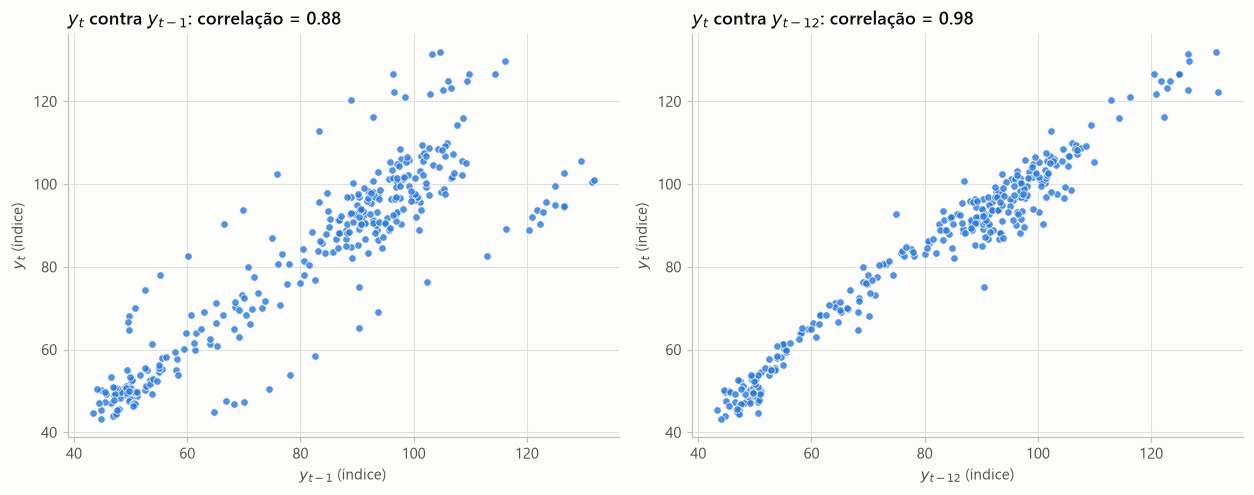

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, k in zip(axs, [1, 12]):
    anterior = vendas.shift(k)
    r = vendas.corr(anterior)
    ax.scatter(anterior, vendas, s=24, color=AZUL, alpha=0.8, edgecolors=FUNDO, linewidths=0.6)
    ax.set_title(f"$y_t$ contra $y_{{t-{k}}}$: correlação = {r:.2f}")
    ax.set_xlabel(f"$y_{{t-{k}}}$ (índice)")
    ax.set_ylabel("$y_t$ (índice)")
plt.tight_layout()
plt.show()

As amostras estão longe de ser independentes. A correlação entre $y_t$ e $y_{t-1}$ é de 0,88, e com $y_{t-12}$ (o mesmo mês do ano anterior) chega a 0,98. Parte dessa correlação vem da tendência comum, mas o fato de o lag 12 superar o lag 1 mostra o peso da sazonalidade. Os pontos afastados da diagonal no gráfico da esquerda são as passagens de novembro para dezembro e de dezembro para janeiro, em que o mês anterior é um péssimo preditor. Na Etapa 4, a FACP vai quantificar quais defasagens trazem informação própria.

### 2.2 Construção do dataset tabular: `create_sliding_window`

Com uma janela de tamanho $p$, cada instante $t$ vira uma linha da tabela:

$$\underbrace{\left[\,y_{t-p},\; y_{t-p+1},\; \dots,\; y_{t-1}\,\right]}_{\text{atributos } \mathbf{x}_t \;(p \text{ defasagens})} \;\longrightarrow\; \underbrace{y_t}_{\text{alvo}}$$

A janela avança ("desliza") uma posição por vez. As $p$ primeiras observações não têm histórico completo e por isso não viram alvo: com $n$ observações, obtemos $n - p$ amostras.

In [13]:
def create_sliding_window(values, window_size):
    """Converte uma série 1D em um par (X, y) de aprendizado supervisionado.

    Cada linha de X contém as `window_size` observações anteriores, da mais antiga
    para a mais recente: [v(t-p), ..., v(t-1)]. O alvo correspondente é v(t).
    Para n valores e janela p, são geradas n - p amostras.
    """
    values = np.asarray(values, dtype=float)
    n = len(values)
    if not 1 <= window_size < n:
        raise ValueError("window_size deve estar entre 1 e len(values) - 1")
    X = np.array([values[t - window_size:t] for t in range(window_size, n)])
    y = values[window_size:]
    return X, y


# Exemplo didático: 6 valores e janela 3 devem gerar 6 - 3 = 3 amostras
X_demo, y_demo = create_sliding_window([10, 20, 30, 40, 50, 60], window_size=3)
print("X =\n", X_demo)
print("y =", y_demo)

X =
 [[10. 20. 30.]
 [20. 30. 40.]
 [30. 40. 50.]]
y = [40. 50. 60.]


### 2.3 Validação dimensional com $p = 12$

Para dados mensais, $p = 12$ é a janela natural: cada amostra "enxerga" um ano completo de histórico, incluindo o mesmo mês do ano anterior ($y_{t-12}$).

In [14]:
p = 12
X, y = create_sliding_window(vendas.to_numpy(), window_size=p)
n = len(vendas)

print(f"n (observações da série) = {n}")
print(f"p (tamanho da janela)    = {p}")
print(f"X.shape = {X.shape}  ->  {X.shape[0]} amostras x {X.shape[1]} atributos (lags)")
print(f"y.shape = {y.shape}")
print(f"n_amostras = n - p = {n} - {p} = {n - p}  ->  confere: {X.shape[0] == n - p}")
assert X.shape == (n - p, p) and y.shape == (n - p,)

n (observações da série) = 319
p (tamanho da janela)    = 12
X.shape = (307, 12)  ->  307 amostras x 12 atributos (lags)
y.shape = (307,)
n_amostras = n - p = 319 - 12 = 307  ->  confere: True


In [15]:
colunas_lags = [f"y(t-{k})" for k in range(p, 0, -1)]
dataset = pd.DataFrame(X, columns=colunas_lags, index=vendas.index[p:])
dataset["alvo y(t)"] = y
dataset.index.name = "data do alvo"
dataset.head(4).round(1)

,y(t-12),y(t-11),y(t-10),y(t-9),y(t-8),y(t-7),y(t-6),y(t-5),y(t-4),y(t-3),y(t-2),y(t-1),alvo y(t)
data do alvo,,,,,,,,,,,,,
2001-01-01,46.6,47.1,49.1,49.1,51.1,48.7,50.4,50.2,49.0,50.0,50.9,70.1,47.4
2001-02-01,47.1,49.1,49.1,51.1,48.7,50.4,50.2,49.0,50.0,50.9,70.1,47.4,44.7
2001-03-01,49.1,49.1,51.1,48.7,50.4,50.2,49.0,50.0,50.9,70.1,47.4,44.7,50.3
2001-04-01,49.1,51.1,48.7,50.4,50.2,49.0,50.0,50.9,70.1,47.4,44.7,50.3,48.1


Cada linha é um exemplo de treino. A primeira (alvo = jan/2001) tem como atributos os 12 meses de 2000; a segunda repete a mesma janela deslocada em um mês. A série 1D virou uma tabela $(X, y)$ que qualquer regressor do *scikit-learn* ou do `statsmodels` aceita. Dois cuidados valem para o restante do trabalho:

- As linhas se sobrepõem no tempo, então a divisão treino/teste precisa ser **temporal**, como discutido em 2.1.
- Em modelos lineares, é melhor aplicar a janela à série já **estacionária** (Etapa 3). No bônus, usamos a mesma função sobre a série transformada, mantendo apenas os lags escolhidos pela FACP (Etapa 4).

## Etapa 3 — Análise de estacionariedade e diferenciação

### 3.1 Teste formal: Dickey-Fuller Aumentado (ADF)

Uma série é **(fracamente) estacionária** quando sua média e sua variância são constantes no tempo e a covariância entre $y_t$ e $y_{t-k}$ depende apenas da defasagem $k$. Os modelos autoregressivos, e as relações aprendidas a partir das janelas deslizantes, pressupõem essa estabilidade: se a distribuição muda, o padrão aprendido no passado deixa de valer no futuro.

O teste ADF estima a regressão

$$\Delta y_t = \alpha + \gamma\, y_{t-1} + \sum_{i=1}^{k} \delta_i\, \Delta y_{t-i} + \varepsilon_t$$

e testa o coeficiente $\gamma$. Os termos defasados $\Delta y_{t-i}$ (a parte "aumentada" do teste) absorvem a autocorrelação, e o número $k$ é escolhido pelo critério AIC (`autolag="AIC"`).

- $H_0$: $\gamma = 0$. A série **possui raiz unitária**, ou seja, é **não estacionária**.
- $H_1$: $\gamma < 0$. A série é **estacionária**.

A estatística segue a distribuição de Dickey-Fuller, e não a *t* de Student, por isso é comparada com valores críticos próprios. **Regra de decisão (α = 0,05):** se o p-valor for menor que 0,05 (o que equivale a estatística menor que o valor crítico de 5%), rejeitamos $H_0$ e concluímos que a série é estacionária. Caso contrário, não há evidência para rejeitar a raiz unitária.

In [16]:
def teste_adf(serie, nome, alpha=0.05, imprimir=True):
    """Executa o ADF (com constante, lags por AIC), imprime o relatório e devolve um resumo."""
    serie = pd.Series(serie).dropna()
    estatistica, p_valor, lags, n_obs, criticos, _ = adfuller(serie, autolag="AIC")
    estacionaria = p_valor < alpha
    if imprimir:
        print(f"Teste ADF: {nome}")
        print(f"  Estatística de teste : {estatistica:.4f}")
        print(f"  p-valor              : {p_valor:.4g}")
        print(f"  Lags usados (AIC)    : {lags}  | observações usadas: {n_obs}")
        print("  Valores críticos     : " + " | ".join(f"{nivel}: {valor:.4f}" for nivel, valor in criticos.items()))
        print("  H0: possui raiz unitária (não estacionária) | H1: estacionária")
        if estacionaria:
            print(f"  Conclusão (α = {alpha}): p < {alpha} -> rejeitamos H0 -> série ESTACIONÁRIA")
        else:
            print(f"  Conclusão (α = {alpha}): p ≥ {alpha} -> não rejeitamos H0 -> série NÃO ESTACIONÁRIA")
    return {"série": nome, "estatística ADF": estatistica, "p-valor": p_valor, "lags (AIC)": lags,
            "crítico 1%": criticos["1%"], "crítico 5%": criticos["5%"], "crítico 10%": criticos["10%"],
            "estacionária (α = 0,05)?": "sim" if estacionaria else "não"}


adf_original = teste_adf(vendas, "série original (nível)")

p_ct = adfuller(vendas, autolag="AIC", regression="ct")[1]
print(f"\nVerificação de robustez, com constante e tendência (regression='ct'): p-valor = {p_ct:.4f}")

Teste ADF: série original (nível)
  Estatística de teste : -1.1779
  p-valor              : 0.683
  Lags usados (AIC)    : 17  | observações usadas: 301
  Valores críticos     : 1%: -3.4523 | 5%: -2.8712 | 10%: -2.5719
  H0: possui raiz unitária (não estacionária) | H1: estacionária
  Conclusão (α = 0.05): p ≥ 0.05 -> não rejeitamos H0 -> série NÃO ESTACIONÁRIA

Verificação de robustez, com constante e tendência (regression='ct'): p-valor = 0.7932


**Conclusão para a série original:** a estatística (−1,18) está bem acima do valor crítico de 5% (−2,87), e o p-valor é 0,683 ≥ 0,05. **Não rejeitamos $H_0$: a série original é não estacionária**, como já sugeriam a tendência e a sazonalidade da Etapa 1. A conclusão se mantém quando incluímos uma tendência determinística no teste (`regression="ct"`, p = 0,79).

### 3.2 Transformação por diferenciação

Seguimos uma sequência de transformações e aplicamos o ADF a cada passo:

1. **$\log y_t$:** estabiliza a variância e torna a sazonalidade aditiva (decisão da Etapa 1). Sozinho, não remove a tendência.
2. **1ª diferença, $\nabla \log y_t = \log y_t - \log y_{t-1}$:** remove a tendência. É aproximadamente a taxa de crescimento mensal.
3. **Diferença sazonal, $\nabla_{12} \log y_t = \log y_t - \log y_{t-12}$:** remove a sazonalidade. É aproximadamente o crescimento em relação ao mesmo mês do ano anterior.
4. **As duas juntas, $\nabla\nabla_{12} \log y_t$:** a variação, de um mês para o outro, da taxa de crescimento anual.

In [17]:
log_vendas = np.log(vendas)
transformacoes = {
    "original (nível)": vendas,
    "log(y)": log_vendas,
    "∇ log(y): 1ª diferença": log_vendas.diff(),
    "∇12 log(y): diferença sazonal": log_vendas.diff(12),
    "∇∇12 log(y): 1ª + sazonal": log_vendas.diff(12).diff(),
}
tabela_adf = pd.DataFrame([teste_adf(s, nome, imprimir=False) for nome, s in transformacoes.items()]).set_index("série")
tabela_adf.style.format({"estatística ADF": "{:.3f}", "p-valor": "{:.4f}", "crítico 1%": "{:.3f}",
                         "crítico 5%": "{:.3f}", "crítico 10%": "{:.3f}"})

,estatística ADF,p-valor,lags (AIC),crítico 1%,crítico 5%,crítico 10%,"estacionária (α = 0,05)?"
série,,,,,,,
original (nível),-1.178,0.6830,17,-3.452,-2.871,-2.572,não
log(y),-1.530,0.5187,17,-3.452,-2.871,-2.572,não
∇ log(y): 1ª diferença,-3.088,0.0274,16,-3.452,-2.871,-2.572,sim
∇12 log(y): diferença sazonal,-2.935,0.0414,12,-3.453,-2.871,-2.572,sim
∇∇12 log(y): 1ª + sazonal,-6.518,0.0000,15,-3.453,-2.872,-2.572,sim


**Leitura da tabela**

- O log sozinho não resolve (p = 0,52): ele estabiliza a variância, mas a tendência continua.
- A **1ª diferença** já passa no ADF (p = 0,027 < 0,05). Pelo critério literal do enunciado, poderíamos parar aqui. Antes disso, porém, vale olhar a FAC dessa série.

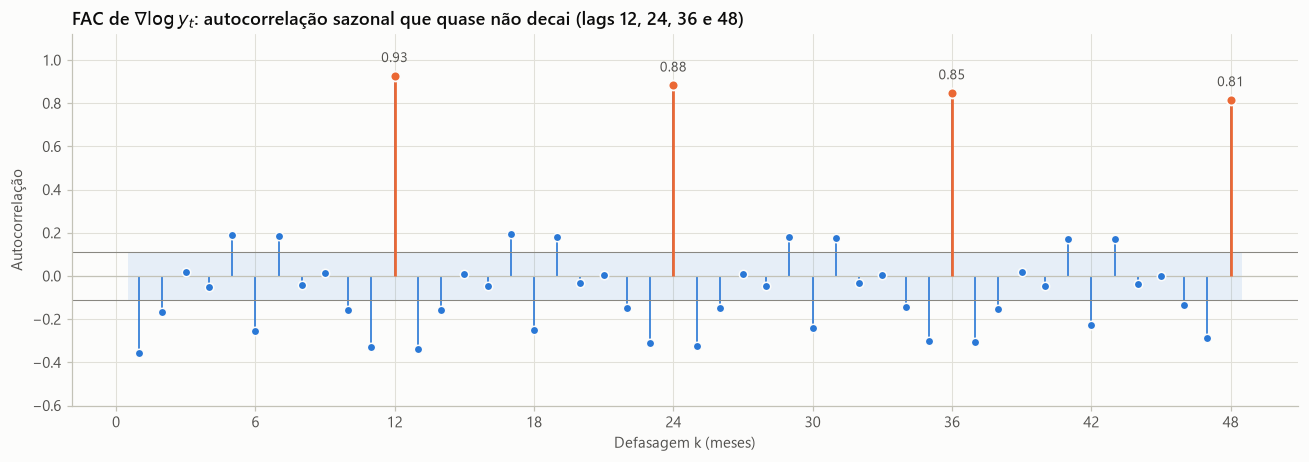

In [18]:
d1 = log_vendas.diff().dropna()
fac_d1 = acf(d1, nlags=48)
picos_sazonais = [12, 24, 36, 48]

fig, ax = plt.subplots(figsize=(12, 4.3))
plot_acf(d1, ax=ax, lags=48, zero=False, bartlett_confint=False, color=AZUL, markersize=5.5,
         markeredgecolor=FUNDO, markeredgewidth=1.0, vlines_kwargs={"colors": AZUL, "linewidth": 1.1},
         title=r"FAC de $\nabla \log y_t$: autocorrelação sazonal que quase não decai (lags 12, 24, 36 e 48)")
estilizar_correlograma(ax, banda=1.96 / np.sqrt(len(d1)))
ax.vlines(picos_sazonais, 0, fac_d1[picos_sazonais], colors=LARANJA, linewidth=1.8, zorder=3)
ax.scatter(picos_sazonais, fac_d1[picos_sazonais], s=42, color=LARANJA, edgecolors=FUNDO, linewidths=1.2, zorder=4)
for k in picos_sazonais:
    ax.annotate(f"{fac_d1[k]:.2f}", xy=(k, fac_d1[k]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=TINTA_2)
ax.set_xticks(range(0, 49, 6))
ax.set_ylim(-0.6, 1.12)
ax.set_xlabel("Defasagem k (meses)")
ax.set_ylabel("Autocorrelação")
plt.tight_layout()
plt.show()

A FAC de $\nabla \log y_t$ tem autocorrelações de **0,93, 0,88 e 0,85 nos lags 12, 24 e 36**, que caem muito devagar. Essa é a assinatura de uma **raiz unitária sazonal**: o padrão de cada mês do calendário persiste de um ano para o outro. O ADF não detecta o problema porque testa apenas a raiz unitária na frequência zero (a da tendência), e não nas frequências sazonais. A lição é que **passar no ADF é necessário, mas não suficiente**: o teste precisa ser lido junto com o gráfico da série e a FAC.

Aplicando também a diferença sazonal, chegamos a $w_t = \nabla\nabla_{12}\log y_t$, com estatística ADF de −6,52, bem abaixo até do valor crítico de 1% (−3,45), e p < 0,0001. A diferença sazonal sozinha ($\nabla_{12}$) fica no limite (p = 0,041) e mantém uma FAC de decaimento lento (0,78 no lag 1), sinal de que ainda resta a raiz unitária da tendência.

**Decisão: as Etapas 4 e o bônus usam $w_t = \nabla\nabla_{12}\log y_t$** (uma diferença simples, $d = 1$, e uma sazonal, $D = 1$). É a mesma transformação do clássico "modelo das companhias aéreas" de Box e Jenkins, o SARIMA$(0,1,1)(0,1,1)_{12}$, criado justamente para séries mensais com tendência e sazonalidade multiplicativa.

In [19]:
w = log_vendas.diff(12).diff().dropna().rename("w")
adf_final = teste_adf(w, "w = ∇∇12 log(y)")
print(f"\nSérie transformada: n = {len(w)} ({w.index[0]:%m/%Y} a {w.index[-1]:%m/%Y}); "
      f"{len(vendas) - len(w)} observações consumidas pelas diferenças (1 + 12)")
print("Maiores valores absolutos de w:", ", ".join(f"{d:%m/%Y} ({v:+.3f})" for d, v in w[w.abs().nlargest(4).index].items()))

Teste ADF: w = ∇∇12 log(y)
  Estatística de teste : -6.5177
  p-valor              : 1.061e-08
  Lags usados (AIC)    : 15  | observações usadas: 290
  Valores críticos     : 1%: -3.4531 | 5%: -2.8716 | 10%: -2.5721
  H0: possui raiz unitária (não estacionária) | H1: estacionária
  Conclusão (α = 0.05): p < 0.05 -> rejeitamos H0 -> série ESTACIONÁRIA

Série transformada: n = 306 (02/2001 a 07/2026); 13 observações consumidas pelas diferenças (1 + 12)
Maiores valores absolutos de w: 04/2021 (+0.191), 04/2020 (-0.177), 05/2020 (+0.111), 03/2003 (-0.105)


### 3.3 Gráfico comparativo: série original × séries diferenciadas

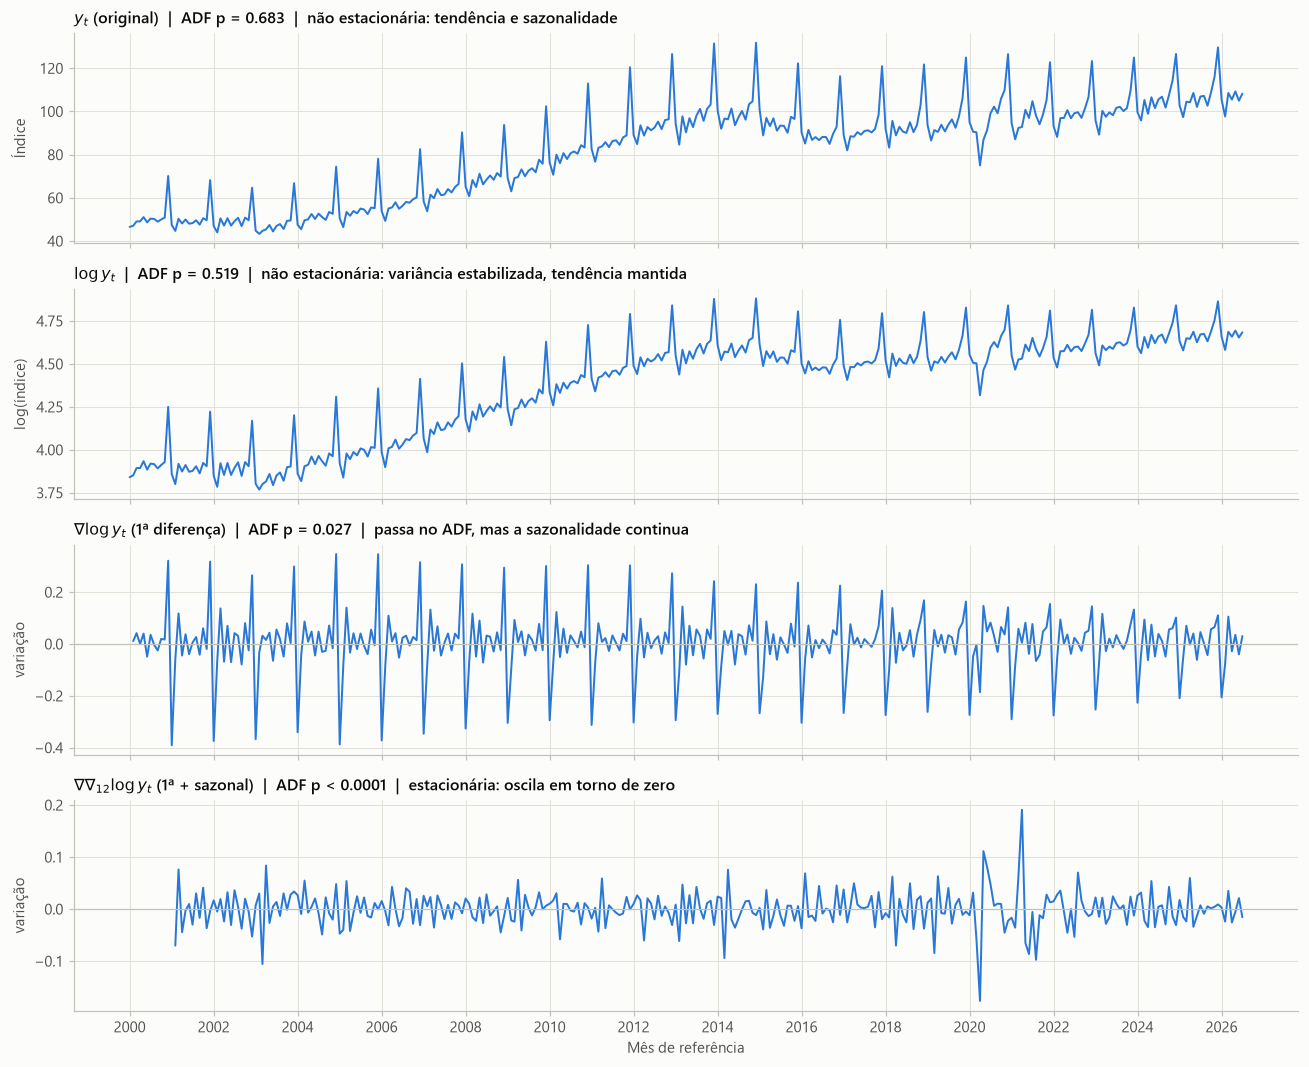

In [20]:
# (série, chave na tabela ADF, título em notação matemática, unidade, leitura)
paineis = [
    (vendas, "original (nível)", r"$y_t$ (original)", "Índice", "não estacionária: tendência e sazonalidade"),
    (log_vendas, "log(y)", r"$\log y_t$", "log(índice)", "não estacionária: variância estabilizada, tendência mantida"),
    (log_vendas.diff(), "∇ log(y): 1ª diferença", r"$\nabla \log y_t$ (1ª diferença)", "variação",
     "passa no ADF, mas a sazonalidade continua"),
    (w, "∇∇12 log(y): 1ª + sazonal", r"$\nabla\nabla_{12} \log y_t$ (1ª + sazonal)", "variação",
     "estacionária: oscila em torno de zero"),
]
fig, axs = plt.subplots(4, 1, figsize=(12, 9.8), sharex=True)
for ax, (serie, chave, titulo, unidade, leitura) in zip(axs, paineis):
    p_valor = tabela_adf.loc[chave, "p-valor"]
    p_txt = "p < 0.0001" if p_valor < 1e-4 else f"p = {p_valor:.3f}"
    ax.plot(serie.index, serie.values, color=AZUL, lw=1.3)
    if serie is not vendas and serie is not log_vendas:
        ax.axhline(0, color=CINZA_MARCA, lw=0.8)
    ax.set_title(f"{titulo}  |  ADF {p_txt}  |  {leitura}", fontsize=10.5)
    ax.set_ylabel(unidade)
axs[-1].set_xlabel("Mês de referência")
formatar_eixo_anos(axs[-1])
fig.align_ylabels(axs)
plt.tight_layout()
plt.show()

A transformação fica clara de cima para baixo. A série original e o log têm tendência evidente. A 1ª diferença remove a tendência, mas mantém "dentes" regulares (saltos em dezembro e quedas em janeiro), que são a sazonalidade que o ADF não capturou. Só no último painel, $w_t = \nabla\nabla_{12}\log y_t$, a série oscila em torno de zero sem padrão repetitivo.

Os maiores valores de $w_t$ estão em 2020–2021: a queda de abril de 2020 (−0,18) e o salto de abril de 2021 (+0,19). O salto é um efeito de base: a diferença sazonal compara cada mês com o mesmo mês do ano anterior, e abril de 2020 estava deprimido. Também aparece um valor atípico em março de 2003 (−0,10), provavelmente um efeito de calendário (o Carnaval caiu em março em 2003 e em fevereiro em 2002). Esta abordagem não trata feriados móveis, e essa é mais uma de suas limitações.

## Etapa 4 — Análise de autocorrelação (FAC/FACP) e seleção de atributos

### 4.1 Correlogramas

- **FAC (ACF)**, $\rho_k = \mathrm{Corr}(w_t, w_{t-k})$: correlação total entre a série e ela mesma defasada em $k$ meses. Inclui efeitos **indiretos**: se $w_t$ depende de $w_{t-1}$, e $w_{t-1}$ depende de $w_{t-2}$, então $w_t$ e $w_{t-2}$ aparecem correlacionados mesmo sem ligação direta.
- **FACP (PACF)**, $\phi_{kk}$: correlação entre $w_t$ e $w_{t-k}$ **depois de remover o efeito linear dos lags intermediários** $w_{t-1}, \dots, w_{t-k+1}$. Equivale ao último coeficiente da regressão autoregressiva de ordem $k$:
$$w_t = \phi_{k1} w_{t-1} + \phi_{k2} w_{t-2} + \dots + \phi_{kk} w_{t-k} + e_t.$$

Usamos 36 defasagens (3 anos) para enxergar a estrutura sazonal em 12, 24 e 36. A faixa sombreada é a banda de significância $\pm 1{,}96/\sqrt{n}$. Na FAC, passamos `bartlett_confint=False` para que ela use essa mesma banda fixa (a opção padrão do `statsmodels`, a fórmula de Bartlett, alarga a banda a cada lag).

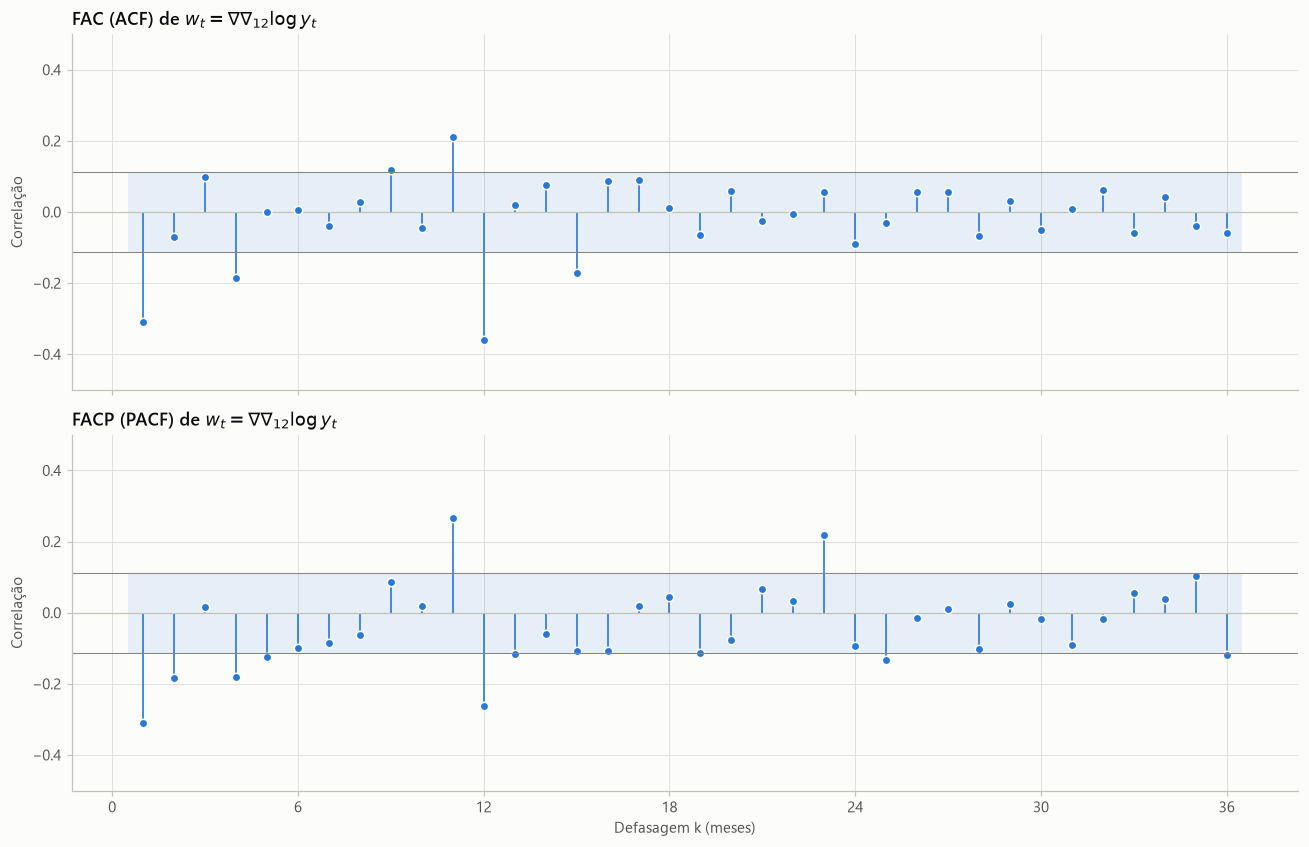

FAC, lags fora da banda: {1: -0.311, 4: -0.185, 9: 0.117, 11: 0.211, 12: -0.361, 15: -0.17}


In [21]:
LAGS = 36
estilo = dict(zero=False, color=AZUL, markersize=5.5, markeredgecolor=FUNDO, markeredgewidth=1.0,
              vlines_kwargs={"colors": AZUL, "linewidth": 1.1})

fig, axs = plt.subplots(2, 1, figsize=(12, 7.8), sharex=True)
plot_acf(w, ax=axs[0], lags=LAGS, bartlett_confint=False,
         title=r"FAC (ACF) de $w_t = \nabla\nabla_{12}\log y_t$", **estilo)
plot_pacf(w, ax=axs[1], lags=LAGS, method="ywm",
          title=r"FACP (PACF) de $w_t = \nabla\nabla_{12}\log y_t$", **estilo)
for ax in axs:
    estilizar_correlograma(ax, banda=1.96 / np.sqrt(len(w)))
    ax.set_xticks(range(0, LAGS + 1, 6))
    ax.set_ylim(-0.5, 0.5)
    ax.set_ylabel("Correlação")
axs[-1].set_xlabel("Defasagem k (meses)")
plt.tight_layout()
plt.show()

valores_fac = acf(w, nlags=LAGS)
fora_da_banda = {k: round(float(valores_fac[k]), 3) for k in range(1, LAGS + 1)
                 if abs(valores_fac[k]) > 1.96 / np.sqrt(len(w))}
print("FAC, lags fora da banda:", fora_da_banda)

**Leitura dos correlogramas**

- **FAC:** os maiores picos são negativos, no **lag 1 (−0,31)** e no **lag 12 (−0,36)**. Os demais lags fora da banda (4, 9, 11 e 15) têm magnitude bem menor. Uma FAC que "corta" logo depois de 1 e de 12 é o padrão típico de componentes de médias móveis (MA) não sazonal e sazonal, coerente com o modelo das companhias aéreas.
- **FACP:** decai de forma mais gradual, com valores significativos no curto prazo e agrupamentos em torno de 12, 24 e 36, que refletem a interação entre a dinâmica de curto prazo e a sazonal. A seleção desses lags é feita a seguir.

### 4.2 Engenharia de atributos orientada por evidência

A banda de significância a 95% é $\pm 1{,}96/\sqrt{n}$. Sob a hipótese de que a autocorrelação parcial verdadeira de um lag é zero, $\hat\phi_{kk}$ tem distribuição aproximadamente normal com desvio-padrão $1/\sqrt{n}$. Um lag é **selecionado** quando $|\hat\phi_{kk}|$ ultrapassa a banda.

In [22]:
n_w = len(w)
banda = 1.96 / np.sqrt(n_w)
valores_facp = pacf(w, nlags=LAGS, method="ywm")  # valores_facp[0] = 1 (lag 0)
lags_significativos = [k for k in range(1, LAGS + 1) if abs(valores_facp[k]) > banda]

print(f"n = {n_w}  ->  banda de significância = ±1.96/√{n_w} = ±{banda:.4f}")
print(f"Lags com |FACP| > banda: {lags_significativos}  ({len(lags_significativos)} de {LAGS})")


def grupo_do_lag(k):
    """Classifica o lag como de curto prazo, sazonal (vizinho de 12, 24 ou 36) ou isolado."""
    if k <= 6:
        return "curto prazo"
    vizinho = min((12, 24, 36), key=lambda s: abs(k - s))
    return f"sazonal (em torno de {vizinho})" if abs(k - vizinho) <= 1 else "isolado"


tabela_lags = pd.DataFrame({
    "FACP": valores_facp[lags_significativos],
    "|FACP| ÷ banda": np.abs(valores_facp[lags_significativos]) / banda,
    "grupo": [grupo_do_lag(k) for k in lags_significativos],
}, index=pd.Index(lags_significativos, name="lag"))
tabela_lags.round(3)

n = 306  ->  banda de significância = ±1.96/√306 = ±0.1120
Lags com |FACP| > banda: [1, 2, 4, 5, 11, 12, 13, 19, 23, 25, 36]  (11 de 36)


,FACP,|FACP| ÷ banda,grupo
lag,,,
1,-0.311,2.772,curto prazo
2,-0.184,1.643,curto prazo
4,-0.180,1.604,curto prazo
5,-0.125,1.113,curto prazo
11,0.266,2.371,sazonal (em torno de 12)
12,-0.262,2.343,sazonal (em torno de 12)
13,-0.115,1.029,sazonal (em torno de 12)
19,-0.115,1.023,isolado
23,0.218,1.949,sazonal (em torno de 24)


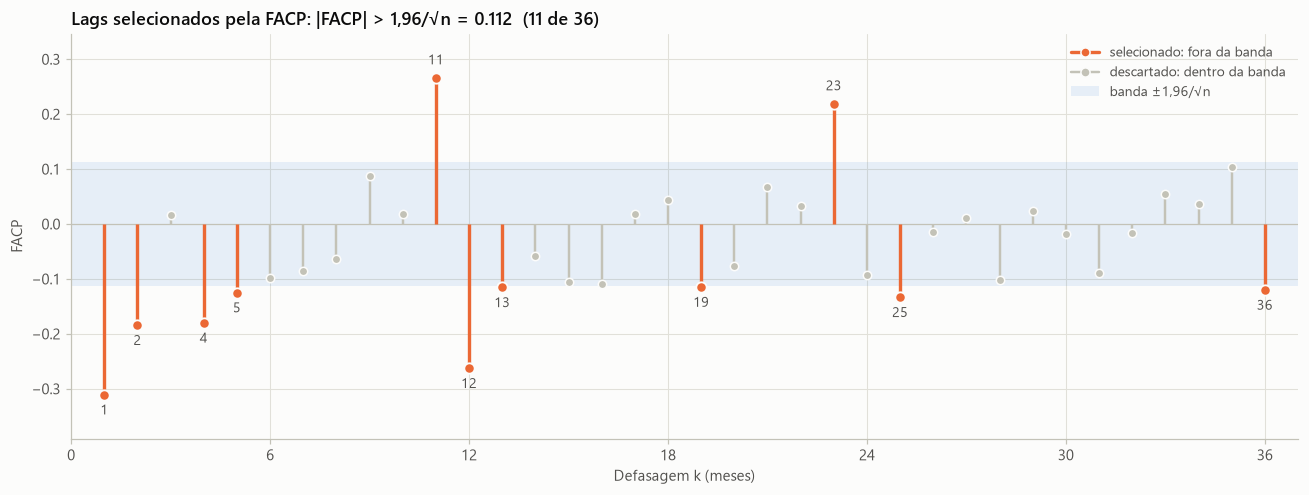

In [23]:
lags_todos = np.arange(1, LAGS + 1)
selecionado = np.isin(lags_todos, lags_significativos)
valores = valores_facp[1:]

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.axhspan(-banda, banda, color=AZUL, alpha=0.10, lw=0)
ax.axhline(0, color=CINZA_MARCA, lw=0.8)
ax.vlines(lags_todos[~selecionado], 0, valores[~selecionado], colors=CINZA_MARCA, linewidth=1.6)
ax.scatter(lags_todos[~selecionado], valores[~selecionado], s=30, color=CINZA_MARCA, edgecolors=FUNDO, linewidths=1, zorder=3)
ax.vlines(lags_todos[selecionado], 0, valores[selecionado], colors=LARANJA, linewidth=2.2)
ax.scatter(lags_todos[selecionado], valores[selecionado], s=46, color=LARANJA, edgecolors=FUNDO, linewidths=1.2, zorder=4)
for k in lags_significativos:
    v = valores_facp[k]
    ax.annotate(str(k), xy=(k, v), xytext=(0, 9 if v > 0 else -13), textcoords="offset points",
                ha="center", fontsize=9, color=TINTA_2)
ax.set_title(f"Lags selecionados pela FACP: |FACP| > 1,96/√n = {banda:.3f}  ({len(lags_significativos)} de {LAGS})")
ax.set_xlabel("Defasagem k (meses)")
ax.set_ylabel("FACP")
ax.set_xticks(range(0, LAGS + 1, 6))
ax.set_xlim(0, LAGS + 1)
ax.set_ylim(min(valores.min(), -banda) - 0.08, max(valores.max(), banda) + 0.08)
ax.legend(handles=[
    Line2D([], [], color=LARANJA, marker="o", lw=2.2, markeredgecolor=FUNDO, label="selecionado: fora da banda"),
    Line2D([], [], color=CINZA_MARCA, marker="o", lw=1.6, markeredgecolor=FUNDO, label="descartado: dentro da banda"),
    Patch(facecolor=AZUL, alpha=0.10, label="banda ±1,96/√n"),
], loc="upper right")
plt.tight_layout()
plt.show()

**Interpretação dos lags selecionados**

| Grupo | Lags | Leitura |
|---|---|---|
| Curto prazo | 1, 2, 4, 5 | FACP negativa: depois de um mês acima do esperado, os meses seguintes tendem a compensar parte do desvio. É um efeito típico de séries diferenciadas (componente MA). |
| Sazonal, em torno de 12 | 11, 12, 13 | O mesmo mês do ano anterior e seus vizinhos. O agrupamento 11–12–13 vem da interação entre o componente de curto prazo e o sazonal, exatamente como no modelo das companhias aéreas. |
| Sazonal, em torno de 24 e 36 | 23, 25, 36 | Ecos da sazonalidade de dois e três anos antes, com intensidade menor. |
| Isolado | 19 | Ultrapassa a banda por muito pouco (0,115 contra 0,112) e não tem interpretação econômica. Com 36 testes a 5%, esperamos cerca de 1,8 "falsos positivos" só por acaso, então este lag é provavelmente espúrio. |

### 4.3 Seleção de lags: a FACP como método de *feature selection*

Na Etapa 2, a janela deslizante gera **um atributo por lag**: com $p = 36$, seriam 36 colunas candidatas. Muitas delas são redundantes. Como a série é autocorrelacionada, $w_{t-2}$ carrega boa parte da informação que já está em $w_{t-1}$, e a FAC mostraria várias correlações que são apenas reflexo umas das outras.

A FACP resolve esse problema porque mede a **contribuição incremental** de cada lag: $\phi_{kk}$ é a correlação de $w_{t-k}$ com o alvo *depois* de descontar tudo o que os lags mais curtos já explicam. Na linguagem de aprendizado de máquina, é um **método de filtro** para seleção de atributos:

1. **Candidatos:** as colunas $w_{t-1}, \dots, w_{t-36}$ da janela deslizante.
2. **Critério:** $|\hat\phi_{kk}| > 1{,}96/\sqrt{n}$, ou seja, a contribuição incremental do lag é estatisticamente diferente de zero.
3. **Resultado:** ficam apenas as colunas que trazem informação nova (aqui, 11 de 36). Isso reduz a dimensionalidade, a multicolinearidade entre atributos, a variância do modelo (menos sobreajuste) e o custo de treino, e ainda torna o modelo mais fácil de interpretar.

**Limitações**

- **Só enxerga dependência linear.** Um lag pode ser útil para um modelo não linear (uma árvore, por exemplo) sem aparecer na FACP.
- **Testes múltiplos.** Com 36 lags testados a 5%, alguns "significativos" serão falsos positivos, como provavelmente o lag 19.
- **A banda é uma aproximação assintótica.** Ela supõe que a FACP verdadeira daquele lag é zero e que $n$ é grande.
- **Vazamento de informação.** Se a FACP for calculada com a série inteira, a seleção "viu" o período de teste. Por isso, no bônus, a FACP é calculada apenas com os dados de treino.

O código abaixo mostra a ligação com a Etapa 2: selecionar lags pela FACP é simplesmente escolher colunas da matriz `X` gerada por `create_sliding_window`.

In [24]:
X_janela, y_janela = create_sliding_window(w.to_numpy(), window_size=LAGS)
coluna_do_lag = {k: LAGS - k for k in range(1, LAGS + 1)}  # a coluna j da janela guarda w(t - (LAGS - j))
X_selecionado = X_janela[:, [coluna_do_lag[k] for k in lags_significativos]]

print(f"Janela completa (p = {LAGS}):        X.shape = {X_janela.shape}")
print(f"Após a FACP ({len(lags_significativos)} lags selecionados): X.shape = {X_selecionado.shape}")
print(f"Redução no número de atributos: {1 - X_selecionado.shape[1] / X_janela.shape[1]:.0%}")

Janela completa (p = 36):        X.shape = (270, 36)
Após a FACP (11 lags selecionados): X.shape = (270, 11)
Redução no número de atributos: 69%


##  — Modelagem autoregressiva com os lags selecionados

O enunciado pede a seleção de atributos, mas não o ajuste de modelos. Como a Etapa 5 pede uma reflexão sobre o *desempenho das abordagens*, foi incluido um experimento curto para verificar se a seleção pela FACP de fato melhora a previsão.

**Desenho do experimento**

- **Alvo:** $w_t = \nabla\nabla_{12}\log y_t$, a série estacionária da Etapa 3. As previsões voltam para o índice pela identidade $\log \hat y_t = \hat w_t + \log y_{t-1} + \log y_{t-12} - \log y_{t-13}$.
- **Atributos:** colunas da janela deslizante de 36 lags (`create_sliding_window`). Todos os modelos usam **as mesmas amostras de treino**, então AIC e BIC são comparáveis entre eles.
- **Divisão temporal:** os últimos 36 meses (ago/2023 a jul/2026) ficam para teste, com previsões de um passo à frente. Nada é embaralhado.
- **Sem vazamento:** os lags da FACP são escolhidos **só com os dados de treino**.
- **Modelos:** regressão linear (OLS do `statsmodels`) com (A) lags 1 a 12, a janela da Etapa 2; (B) lags 1 a 36, a janela completa; (C) apenas os lags da FACP. Como referência, dois modelos ingênuos: o *ingênuo sazonal* ($\hat y_t = y_{t-12}$) e o *ingênuo de crescimento sazonal* ($\hat w_t = 0$), que supõe que o mês cresce em relação ao anterior o mesmo que cresceu um ano antes.
- **Métricas, no nível do índice:** MAPE (erro percentual absoluto médio) e RMSE.

In [25]:
N_TESTE = 36
X_janela, y_janela = create_sliding_window(w.to_numpy(), window_size=LAGS)
datas_alvo = w.index[LAGS:]
treino = np.arange(len(y_janela)) < len(y_janela) - N_TESTE
teste = ~treino
datas_teste = datas_alvo[teste]

# FACP calculada só com o período de treino (evita vazamento de informação do teste)
w_treino = w[w.index < datas_teste[0]]
banda_treino = 1.96 / np.sqrt(len(w_treino))
facp_treino = pacf(w_treino, nlags=LAGS, method="ywm")
lags_facp_treino = [k for k in range(1, LAGS + 1) if abs(facp_treino[k]) > banda_treino]

print(f"Amostras: {treino.sum()} de treino (alvos de {datas_alvo[treino][0]:%m/%Y} a {datas_alvo[treino][-1]:%m/%Y}) "
      f"e {teste.sum()} de teste ({datas_teste[0]:%m/%Y} a {datas_teste[-1]:%m/%Y})")
print(f"FACP no treino (n = {len(w_treino)}, banda ±{banda_treino:.4f}): lags selecionados = {lags_facp_treino}")

Amostras: 234 de treino (alvos de 02/2004 a 07/2023) e 36 de teste (08/2023 a 07/2026)
FACP no treino (n = 270, banda ±0.1193): lags selecionados = [1, 2, 4, 5, 11, 12, 23, 25]


In [26]:
log_v = np.log(vendas)
base_log = (log_v.shift(1) + log_v.shift(12) - log_v.shift(13)).loc[datas_teste].to_numpy()
y_real = vendas.loc[datas_teste].to_numpy()


def mape(real, previsto):
    return np.mean(np.abs((real - previsto) / real)) * 100


def rmse(real, previsto):
    return np.sqrt(np.mean((real - previsto) ** 2))


especificacoes = {
    "OLS: lags da FACP": lags_facp_treino,
    "OLS: lags 1 a 12": list(range(1, 13)),
    "OLS: lags 1 a 36": list(range(1, LAGS + 1)),
}
linhas, previsoes = [], {}
for nome, lags in especificacoes.items():
    colunas = [coluna_do_lag[k] for k in lags]
    X_tr = sm.add_constant(X_janela[treino][:, colunas])
    X_te = sm.add_constant(X_janela[teste][:, colunas], has_constant="add")
    modelo = sm.OLS(y_janela[treino], X_tr).fit()
    previsoes[nome] = np.exp(modelo.predict(X_te) + base_log)  # volta de w para o índice
    linhas.append({"modelo": nome, "atributos": len(lags), "R² aj. (treino)": modelo.rsquared_adj,
                   "AIC (treino)": modelo.aic, "BIC (treino)": modelo.bic,
                   "MAPE teste (%)": mape(y_real, previsoes[nome]), "RMSE teste": rmse(y_real, previsoes[nome])})

ingenuos = {
    "Ingênuo de crescimento sazonal (w = 0)": np.exp(base_log),
    "Ingênuo sazonal: y(t-12)": vendas.shift(12).loc[datas_teste].to_numpy(),
}
for nome, previsto in ingenuos.items():
    previsoes[nome] = previsto
    linhas.append({"modelo": nome, "atributos": 0, "MAPE teste (%)": mape(y_real, previsto),
                   "RMSE teste": rmse(y_real, previsto)})

comparacao = pd.DataFrame(linhas).set_index("modelo").sort_values("MAPE teste (%)")
comparacao.style.format({"R² aj. (treino)": "{:.3f}", "AIC (treino)": "{:.1f}", "BIC (treino)": "{:.1f}",
                         "MAPE teste (%)": "{:.2f}", "RMSE teste": "{:.3f}"}, na_rep="—")

,atributos,R² aj. (treino),AIC (treino),BIC (treino),MAPE teste (%),RMSE teste
modelo,,,,,,
OLS: lags da FACP,8,0.268,-960.4,-929.3,1.44,1.914
OLS: lags 1 a 12,12,0.263,-955.1,-910.2,1.60,2.058
Ingênuo de crescimento sazonal (w = 0),0,—,—,—,2.04,2.627
OLS: lags 1 a 36,36,0.357,-966.1,-838.2,2.06,3.077
Ingênuo sazonal: y(t-12),0,—,—,—,2.49,3.218


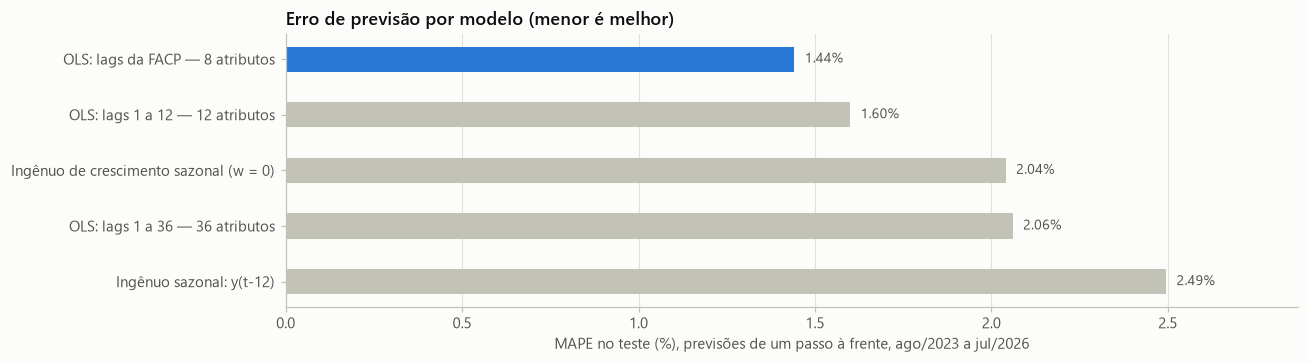

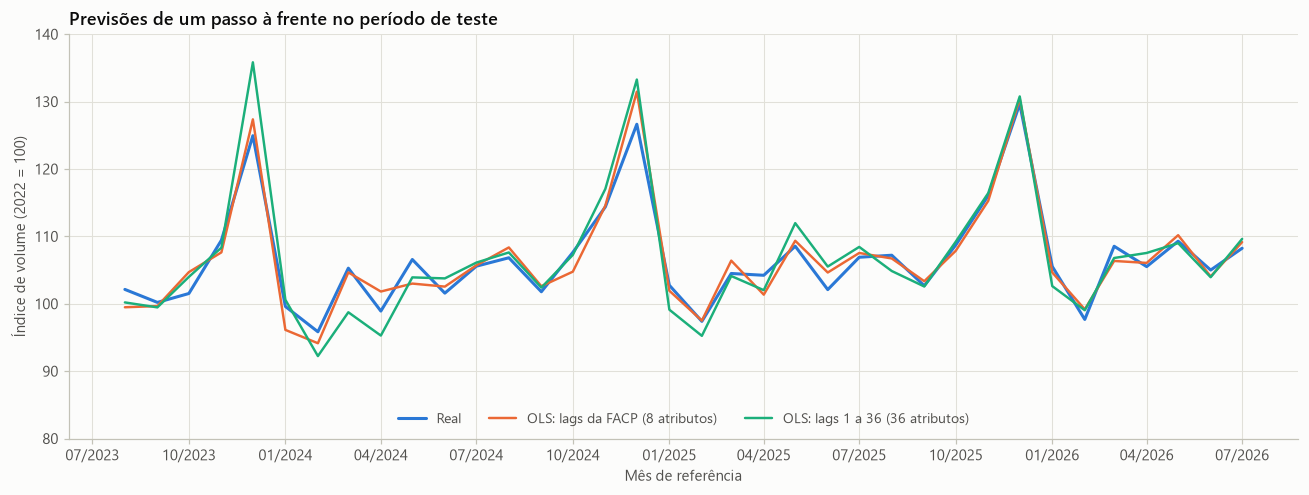

In [27]:
melhor = comparacao.index[0]
ordem = comparacao.iloc[::-1]  # barh desenha de baixo para cima: o melhor fica no topo

fig, ax = plt.subplots(figsize=(12, 3.4))
cores = [AZUL if nome == melhor else CINZA_MARCA for nome in ordem.index]
ax.barh(range(len(ordem)), ordem["MAPE teste (%)"], color=cores, height=0.45)
ax.set_yticks(range(len(ordem)), [f"{nome} — {int(a)} atributos" if a else nome
                                  for nome, a in zip(ordem.index, ordem["atributos"])])
for i, valor in enumerate(ordem["MAPE teste (%)"]):
    ax.text(valor + 0.03, i, f"{valor:.2f}%", va="center", fontsize=9, color=TINTA_2)
ax.set_xlim(0, ordem["MAPE teste (%)"].max() * 1.15)
ax.set_xlabel("MAPE no teste (%), previsões de um passo à frente, ago/2023 a jul/2026")
ax.set_title("Erro de previsão por modelo (menor é melhor)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(datas_teste, y_real, color=AZUL, lw=2, label="Real")
ax.plot(datas_teste, previsoes["OLS: lags da FACP"], color=LARANJA, lw=1.6,
        label=f"OLS: lags da FACP ({len(lags_facp_treino)} atributos)")
ax.plot(datas_teste, previsoes["OLS: lags 1 a 36"], color=VERDE_AGUA, lw=1.6, label="OLS: lags 1 a 36 (36 atributos)")
ax.set_title("Previsões de um passo à frente no período de teste")
ax.set_xlabel("Mês de referência")
ax.set_ylabel("Índice de volume (2022 = 100)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_ylim(80, 140)
ax.legend(loc="lower center", ncol=3)
plt.tight_layout()
plt.show()

**Resultados**

- **O modelo com os lags da FACP foi o melhor no teste.** Com MAPE de 1,44% e apenas 8 atributos, errou 10% menos que a janela de 12 lags (1,60%), 30% menos que a janela completa de 36 lags (2,06%) e 42% menos que o ingênuo sazonal (2,49%).
- **Mais atributos não significa modelo melhor.** A janela completa teve o melhor ajuste no treino (R² ajustado de 0,357 e o menor AIC), mas o pior desempenho entre os modelos OLS no teste. Ficou até ligeiramente atrás do ingênuo de crescimento sazonal (2,04%), que não estima nenhum parâmetro. É o retrato do **sobreajuste**: com 36 coeficientes para 234 amostras, o modelo aprende o ruído do treino. O BIC, que penaliza mais o número de parâmetros, aponta corretamente o modelo da FACP como o melhor (−929,3).
- **A seleção feita só com o treino foi estável.** Ela escolheu 8 lags (1, 2, 4, 5, 11, 12, 23 e 25), todos contidos nos 11 encontrados com a série inteira. Ficaram de fora o lag isolado 19 e os lags 13 e 36, que eram os mais próximos da banda, o que reforça a suspeita de que eram frágeis.

**Limitações do experimento:** Foi usado uma única divisão treino/teste de 36 meses e não foi testado se as diferenças entre modelos são estatisticamente significativas (por exemplo, com o teste de Diebold-Mariano). Além disso, o modelo é linear e as previsões são de um passo à frente. Os próximos passos naturais seriam a validação com origem móvel (`TimeSeriesSplit`), um SARIMA$(0,1,1)(0,1,1)_{12}$ como referência estatística e modelos não lineares (*random forest*, *gradient boosting*) treinados com os mesmos atributos.

## Etapa 5 — Considerações finais e avaliação pessoal

### 5.1 Síntese dos resultados e análises

1. **Decomposição (Etapa 1).** O varejo brasileiro combina uma tendência com ciclos marcados (expansão até 2014, recessão em 2015–2016, recuperação lenta e o choque transitório da COVID-19) com uma sazonalidade forte: dezembro fica cerca de 30% acima da tendência e fevereiro, cerca de 11% abaixo. A amplitude sazonal cresceu na mesma proporção do nível (β = 0,79 entre 2001 e 2014), o que indica um **modelo multiplicativo** e justifica o uso de $\log y_t$. A análise também mostrou um limite da decomposição clássica: o padrão sazonal **mudou** ao longo do tempo, com dezembro perdendo peso para novembro (Black Friday), e o resíduo absorveu essa mudança.
2. **Janelas deslizantes (Etapa 2).** A função `create_sliding_window` transformou a série de 319 pontos em uma tabela supervisionada com $319 - 12 = 307$ amostras e 12 atributos. Isso torna explícita a dependência temporal que quebra a hipótese i.i.d. e exige que a divisão entre treino e teste respeite o tempo.
3. **Estacionariedade (Etapa 3).** A série original é não estacionária (ADF p = 0,683). A 1ª diferença do log passou no ADF (p = 0,027), mas a FAC revelou uma raiz unitária sazonal (autocorrelações de 0,93, 0,88 e 0,85 nos lags 12, 24 e 36) que o teste não detecta. Só a combinação $\nabla\nabla_{12}\log y_t$ produziu uma série estacionária de forma robusta (estatística −6,52, p < 0,0001).
4. **Autocorrelação (Etapa 4).** A FACP selecionou 11 dos 36 lags, em grupos com interpretação clara: curto prazo (1, 2, 4, 5) e sazonal (11–13, 23, 25, 36), além de um lag isolado (19), provavelmente espúrio. A FAC, com picos negativos em 1 e 12, aponta para uma estrutura do tipo SARIMA$(0,1,1)(0,1,1)_{12}$.
5. **Bônus.** Usar os lags da FACP como atributos levou ao menor erro de previsão (MAPE de 1,44%) com menos atributos do que a janela completa, que sobreajustou (2,06%). Esse resultado concretiza a ponte proposta pela disciplina: **o diagnóstico estatístico clássico orientou a engenharia de atributos de um modelo de aprendizado supervisionado**.

### 5.2 Avaliação pessoal do desenvolvimento

**Fluxo de trabalho.** O trabalho foi organizado em um único notebook, na ordem das etapas do enunciado: escolher e validar a série, explorar, transformar, testar e, por fim, selecionar atributos. Usei o CHAT GPT como apoio durante o desenvolvimento: escrever conclusões e revisar o código. As decisões de escopo foram minhas: a escolha da série do varejo entre as opções levantadas, a entrega em notebook e a inclusão da Modelagem autoregressiva com os lags selecionados. Cada número citado no texto foi conferido com as saídas do notebook executado.

**Desafios superados**

- *Dados e ambiente.* A primeira dificuldade foi prática. A API do Banco Central, uma das fontes avaliadas na escolha da série, estava fora do ar, e a API do IBGE respondia em formato comprimido (gzip), o que exigiu tratamento no código. A instalação de Python também não tinha o `statsmodels`, e foi preciso criar um ambiente virtual separado. Como o IBGE revisa a série a cada divulgação, os dados foram salvos em CSV para que os resultados descritos no texto continuem reproduzíveis.
- *ADF × FAC.* O ponto conceitual mais difícil foi entender por que a 1ª diferença "passava" no ADF (p = 0,027) e, mesmo assim, não estava adequada. Seria tentador parar ali, como o enunciado permitiria. Só a FAC, com autocorrelação de 0,93 no lag 12 e quase sem decaimento, revelou a raiz unitária sazonal que o ADF não testa.
- *Aditivo × multiplicativo.* A escolha parecia óbvia no gráfico, mas os dados contaram uma história em duas fases: comportamento multiplicativo até 2014 e um padrão sazonal em mudança depois. Foi preciso transformar a intuição visual em uma medida (a elasticidade da amplitude em relação ao nível) para justificar a decisão.

**Desempenho das abordagens.** A decomposição clássica descreveu bem a série, mas tem limites claros: supõe sazonalidade fixa e é sensível a choques como o da COVID-19. O ADF se mostrou necessário, mas não suficiente, e precisou ser lido junto com a FAC. A FACP funcionou muito bem como filtro de atributos: no bônus, o modelo com os 8 lags selecionados teve o menor erro (MAPE de 1,44%), enquanto a janela completa de 36 lags sobreajustou (2,06%).

### 5.3 Autoavaliação do aprendizado

O aprendizado mais importante foi entender, na prática, **por que uma série temporal não é um conjunto de dados i.i.d.** A definição ganhou sentido concreto ao ver a janela deslizante montada: cada linha da tabela compartilha 11 dos 12 valores com a linha vizinha, e $y_t$ tem correlação de 0,98 com $y_{t-12}$. Embaralhar esses dados ou usar *k-fold* aleatório colocaria o futuro dentro do treino. Por isso o bônus usa divisão temporal e calcula a FACP só com os dados de treino, um cuidado que só ficou claro ao passar pelo processo.

O segundo aprendizado foi **ler a FAC e a FACP** como ferramentas complementares. A FAC mostra a correlação total, inclusive os efeitos indiretos, e por isso revelou a sazonalidade persistente na Etapa 3. A FACP isola a contribuição de cada lag e por isso serve como filtro de atributos na Etapa 4. Interpretar os agrupamentos em torno de 12, 24 e 36, e reconhecer que o lag 19 provavelmente era um falso positivo dos testes múltiplos, mostrou que significância estatística não é o mesmo que relevância. Ver a banda $\pm 1{,}96/\sqrt{n}$ calculada no código coincidir com a faixa desenhada pelo `plot_pacf` tirou o "mistério" do gráfico.

A prática fixou os conceitos porque uma série real não se comporta como os exemplos de aula. A sazonalidade mudou com o tempo, a pandemia gerou valores extremos e um teste "passou" quando não deveria. Cada um desses desvios exigiu voltar à teoria para decidir o que fazer, e foi nesse vaivém entre resultado e conceito que o conteúdo da disciplina se consolidou.

### 5.4 Pontos de destaque

**O ponto mais interessante foi encontrar, nos próprios dados, o efeito da Black Friday sobre a sazonalidade do varejo.** Entre 2000–2009 e 2021–2025, o peso de dezembro caiu de 1,38 para 1,22 vez a média do ano, enquanto o de novembro subiu de 1,01 para 1,07. A mudança ganha força na segunda metade da década de 2010, alguns anos depois da primeira edição da Black Friday no Brasil, em 2010.

Escolhi esse destaque por três motivos:

1. **Não estava no roteiro.** A descoberta surgiu de uma anomalia que pedia explicação: a amplitude sazonal relativa caindo depois de 2014. Foi o momento em que a análise exploratória fez jus ao nome.
2. **Mostrou um limite concreto de um método da disciplina.** A decomposição clássica supõe um padrão sazonal fixo, e o erro dessa hipótese apareceu exatamente onde deveria: no resíduo, com dezembros recentes negativos e novembros positivos.
3. **Ligou a estatística ao comportamento real das pessoas.** Os números mostram consumidores antecipando parte das compras de Natal para novembro. Com isso, a análise deixou de ser um exercício e passou a contar algo sobre a economia.

## Referências

- BOX, G. E. P.; JENKINS, G. M.; REINSEL, G. C.; LJUNG, G. M. *Time Series Analysis: Forecasting and Control*. 5. ed. Hoboken: Wiley, 2015.
- DICKEY, D. A.; FULLER, W. A. Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, v. 74, n. 366, p. 427–431, 1979.
- HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021. Disponível em: <https://otexts.com/fpp3/>.
- IBGE. *Pesquisa Mensal de Comércio — Tabela 8880*. Sistema IBGE de Recuperação Automática (SIDRA). Disponível em: <https://sidra.ibge.gov.br/tabela/8880>. Acesso em: 2 out. 2026.
- SEABOLD, S.; PERKTOLD, J. statsmodels: econometric and statistical modeling with Python. In: *Proceedings of the 9th Python in Science Conference*, 2010.